<a href="https://colab.research.google.com/github/KellyVNguyen/Predicting-Injury-Severity-using-Crash-Report-Drivers-Data/blob/main/tabular/(final)_Data_4380_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Research Question

What factors/characteristics contribute to injury severity from the years 2022-2025?

#Initialization
load dataset

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import seaborn as sns
import re

In [ ]:
df = pd.read_csv("/content/export (1).csv", low_memory=False)

print("Original shape:", df.shape)
display(df.head())

Original shape: (219335, 39)


,Report Number,Local Case Number,Agency Name,ACRS Report Type,Crash Date/Time,Route Type,Road Name,Cross-Street Name,Off-Road Description,Municipality,...,Vehicle Going Dir,Speed Limit,Driverless Vehicle,Parked Vehicle,Vehicle Year,Vehicle Make,Vehicle Model,Latitude,Longitude,Location
0,MCP25030037,260036214,MONTGOMERY,Property Damage Crash,08/19/2026 08:35:00 AM,Maryland (State) Route,DARNESTOWN RD,NaN,NaN,NaN,...,Eastbound,50,No,No,2021,PETERBILT,567,39.206122,-77.435362,"(39.20612167, -77.43536167)"
1,MCP3498000B,260036212,MONTGOMERY,Injury Crash,08/19/2026 08:32:00 AM,County Route,MONTROSE RD (WB/L),NaN,NaN,NaN,...,Westbound,35,No,No,2017,INFINITI,Q60,39.054472,-77.142530,"(39.05447194, -77.14252951)"
2,MCP3498000B,260036212,MONTGOMERY,Injury Crash,08/19/2026 08:32:00 AM,County Route,MONTROSE RD (WB/L),NaN,NaN,NaN,...,Westbound,35,No,No,2017,FORD,F-650,39.054472,-77.142530,"(39.05447194, -77.14252951)"
3,MCP3274003Q,260036206,MONTGOMERY,Property Damage Crash,08/19/2026 07:46:00 AM,Maryland (State) Route,OLD GEORGETOWN RD,NaN,NaN,NaN,...,Eastbound,35,No,No,2017,CHEVROLET,BOLT EV,38.993068,-77.107693,"(38.993068, -77.10769322)"
4,MCP3274003Q,260036206,MONTGOMERY,Property Damage Crash,08/19/2026 07:46:00 AM,Maryland (State) Route,OLD GEORGETOWN RD,NaN,NaN,NaN,...,Northbound,35,No,No,2024,RIVIAN,R1S,38.993068,-77.107693,"(38.993068, -77.10769322)"


# Inspect raw dataset
- This documents the starting state of the data, which will help  explain the dataset's quality and preprocessing decisions in the presentation.

In [ ]:
# Preserve the original data
df_raw = df.copy()

print("Original shape:", df_raw.shape)
print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nData types:")
print(df_raw.dtypes)

# Missing-value summary
missing_summary = pd.DataFrame({
    "Missing Count": df_raw.isna().sum(),
    "Missing Percent": df_raw.isna().mean().mul(100).round(2),
    "Data Type": df_raw.dtypes.astype(str)
}).sort_values("Missing Percent", ascending=False)

print("\nMissing-value summary:")
display(missing_summary)

# Exact duplicate rows
print("\nExact duplicate rows:", df_raw.duplicated().sum())

# Target distribution
print("\nInjury severity distribution:")
print(df_raw["Injury Severity"].value_counts(dropna=False))

# Unique categories for important variables
categorical_cols = [
    "Injury Severity",
    "Collision Type",
    "Weather",
    "Surface Condition",
    "Light",
    "Traffic Control"
]

for col in categorical_cols:
    print(f"\n{col}: {df_raw[col].nunique(dropna=True)} unique values")
    print(df_raw[col].value_counts(dropna=False).head(20))

Original shape: (219335, 39)

Column names:
['Report Number', 'Local Case Number', 'Agency Name', 'ACRS Report Type', 'Crash Date/Time', 'Route Type', 'Road Name', 'Cross-Street Name', 'Off-Road Description', 'Municipality', 'Related Non-Motorist', 'Collision Type', 'Weather', 'Surface Condition', 'Light', 'Traffic Control', 'Driver Substance Abuse', 'Non-Motorist Substance Abuse', 'Person ID', 'Driver At Fault', 'Injury Severity', 'Circumstance', 'Driver Distracted By', 'Drivers License State', 'Vehicle ID', 'Vehicle Damage Extent', 'Vehicle First Impact Location', 'Vehicle Body Type', 'Vehicle Movement', 'Vehicle Going Dir', 'Speed Limit', 'Driverless Vehicle', 'Parked Vehicle', 'Vehicle Year', 'Vehicle Make', 'Vehicle Model', 'Latitude', 'Longitude', 'Location']

Data types:
Report Number                     object
Local Case Number                 object
Agency Name                       object
ACRS Report Type                  object
Crash Date/Time                   object
Route 

,Missing Count,Missing Percent,Data Type
Non-Motorist Substance Abuse,213240,97.22,object
Related Non-Motorist,212094,96.70,object
Municipality,200209,91.28,object
Off-Road Description,198755,90.62,object
Circumstance,176366,80.41,object
Cross-Street Name,46128,21.03,object
Driver Substance Abuse,31320,14.28,object
Traffic Control,30071,13.71,object
Road Name,26276,11.98,object
Surface Condition,25008,11.40,object



Exact duplicate rows: 0

Injury severity distribution:
Injury Severity
NO APPARENT INJURY          141196
No Apparent Injury           36194
POSSIBLE INJURY              17481
SUSPECTED MINOR INJURY       11871
Suspected Minor Injury        4007
NaN                           3452
Possible Injury               3138
SUSPECTED SERIOUS INJURY      1414
Suspected Serious Injury       376
FATAL INJURY                   154
Fatal Injury                    52
Name: count, dtype: int64

Injury Severity: 10 unique values
Injury Severity
NO APPARENT INJURY          141196
No Apparent Injury           36194
POSSIBLE INJURY              17481
SUSPECTED MINOR INJURY       11871
Suspected Minor Injury        4007
NaN                           3452
Possible Injury               3138
SUSPECTED SERIOUS INJURY      1414
Suspected Serious Injury       376
FATAL INJURY                   154
Fatal Injury                    52
Name: count, dtype: int64

Collision Type: 28 unique values
Collision Type
SAME D

# Standardize column names and text formatting

In [ ]:
df_clean = df_raw.copy()

# Standardize column names
df_clean.columns = df_clean.columns.str.strip()

# Standardize text whitespace without changing internal wording
text_cols = df_clean.select_dtypes(
    include=["object", "string"]
).columns

for col in text_cols:
    df_clean[col] = df_clean[col].map(
        lambda x: re.sub(r"\s+", " ", x).strip()
        if isinstance(x, str)
        else x
    )

# Convert empty strings and whitespace-only strings to NaN
df_clean[text_cols] = df_clean[text_cols].replace(
    r"^\s*$", np.nan, regex=True
)

print("Shape after text cleanup:", df_clean.shape)

Shape after text cleanup: (219335, 39)


# Parse the crash date and time

In [ ]:
# Parse crash date/time
df_clean["Crash Date/Time"] = pd.to_datetime(
    df_clean["Crash Date/Time"],
    errors="coerce"
)

invalid_dates = df_clean["Crash Date/Time"].isna().sum()

print("Missing or invalid crash dates:", invalid_dates)
print("Earliest crash:", df_clean["Crash Date/Time"].min())
print("Latest crash:", df_clean["Crash Date/Time"].max())

# Investigate invalid raw date strings
invalid_date_rows = df_clean.loc[
    df_clean["Crash Date/Time"].isna()
].copy()

Missing or invalid crash dates: 0
Earliest crash: 2015-01-01 00:30:00
Latest crash: 2026-08-19 08:35:00


# Inspect missing rows

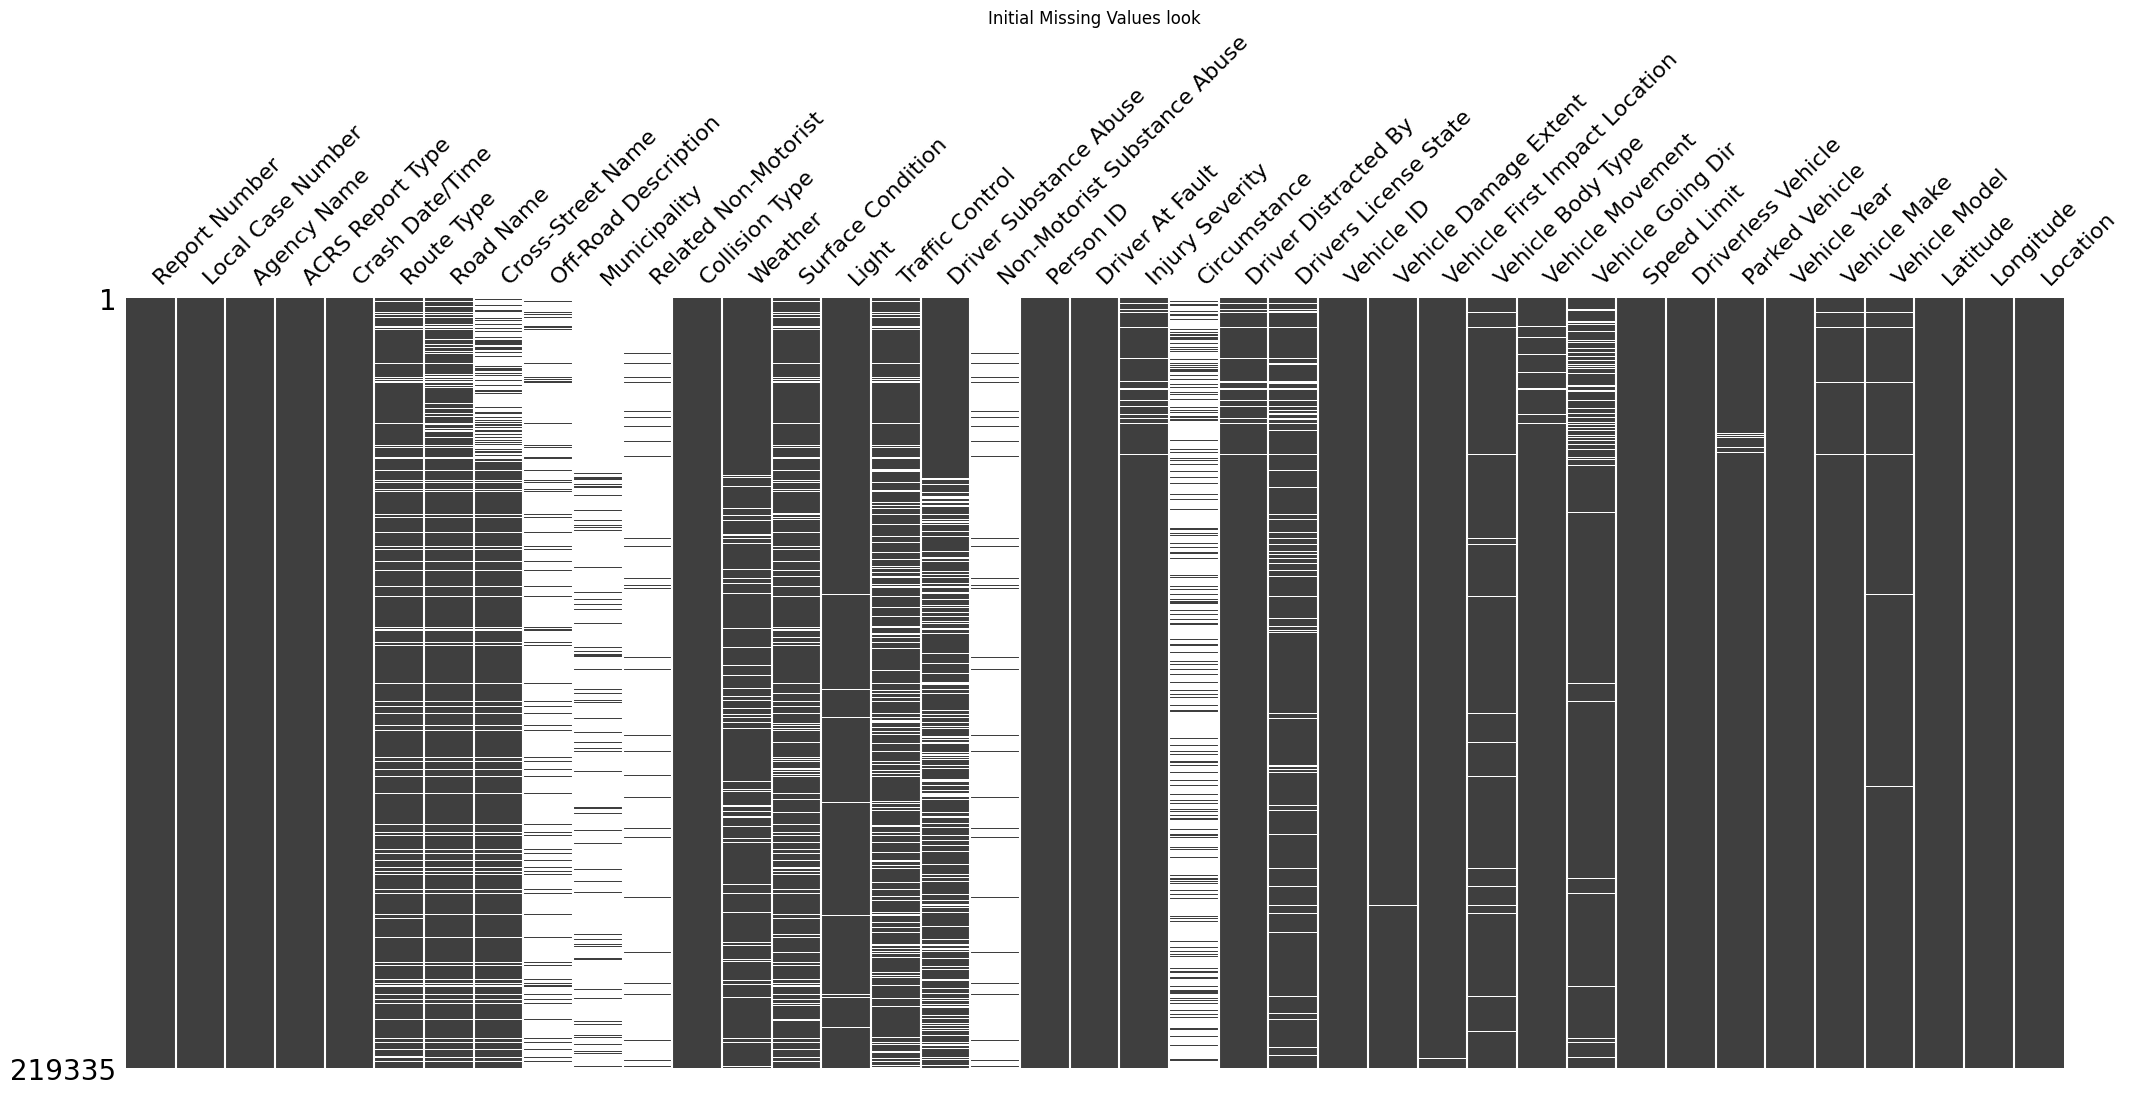

In [ ]:
msno.matrix(df_clean, sparkline=False)
plt.title("Initial Missing Values look")
plt.show()

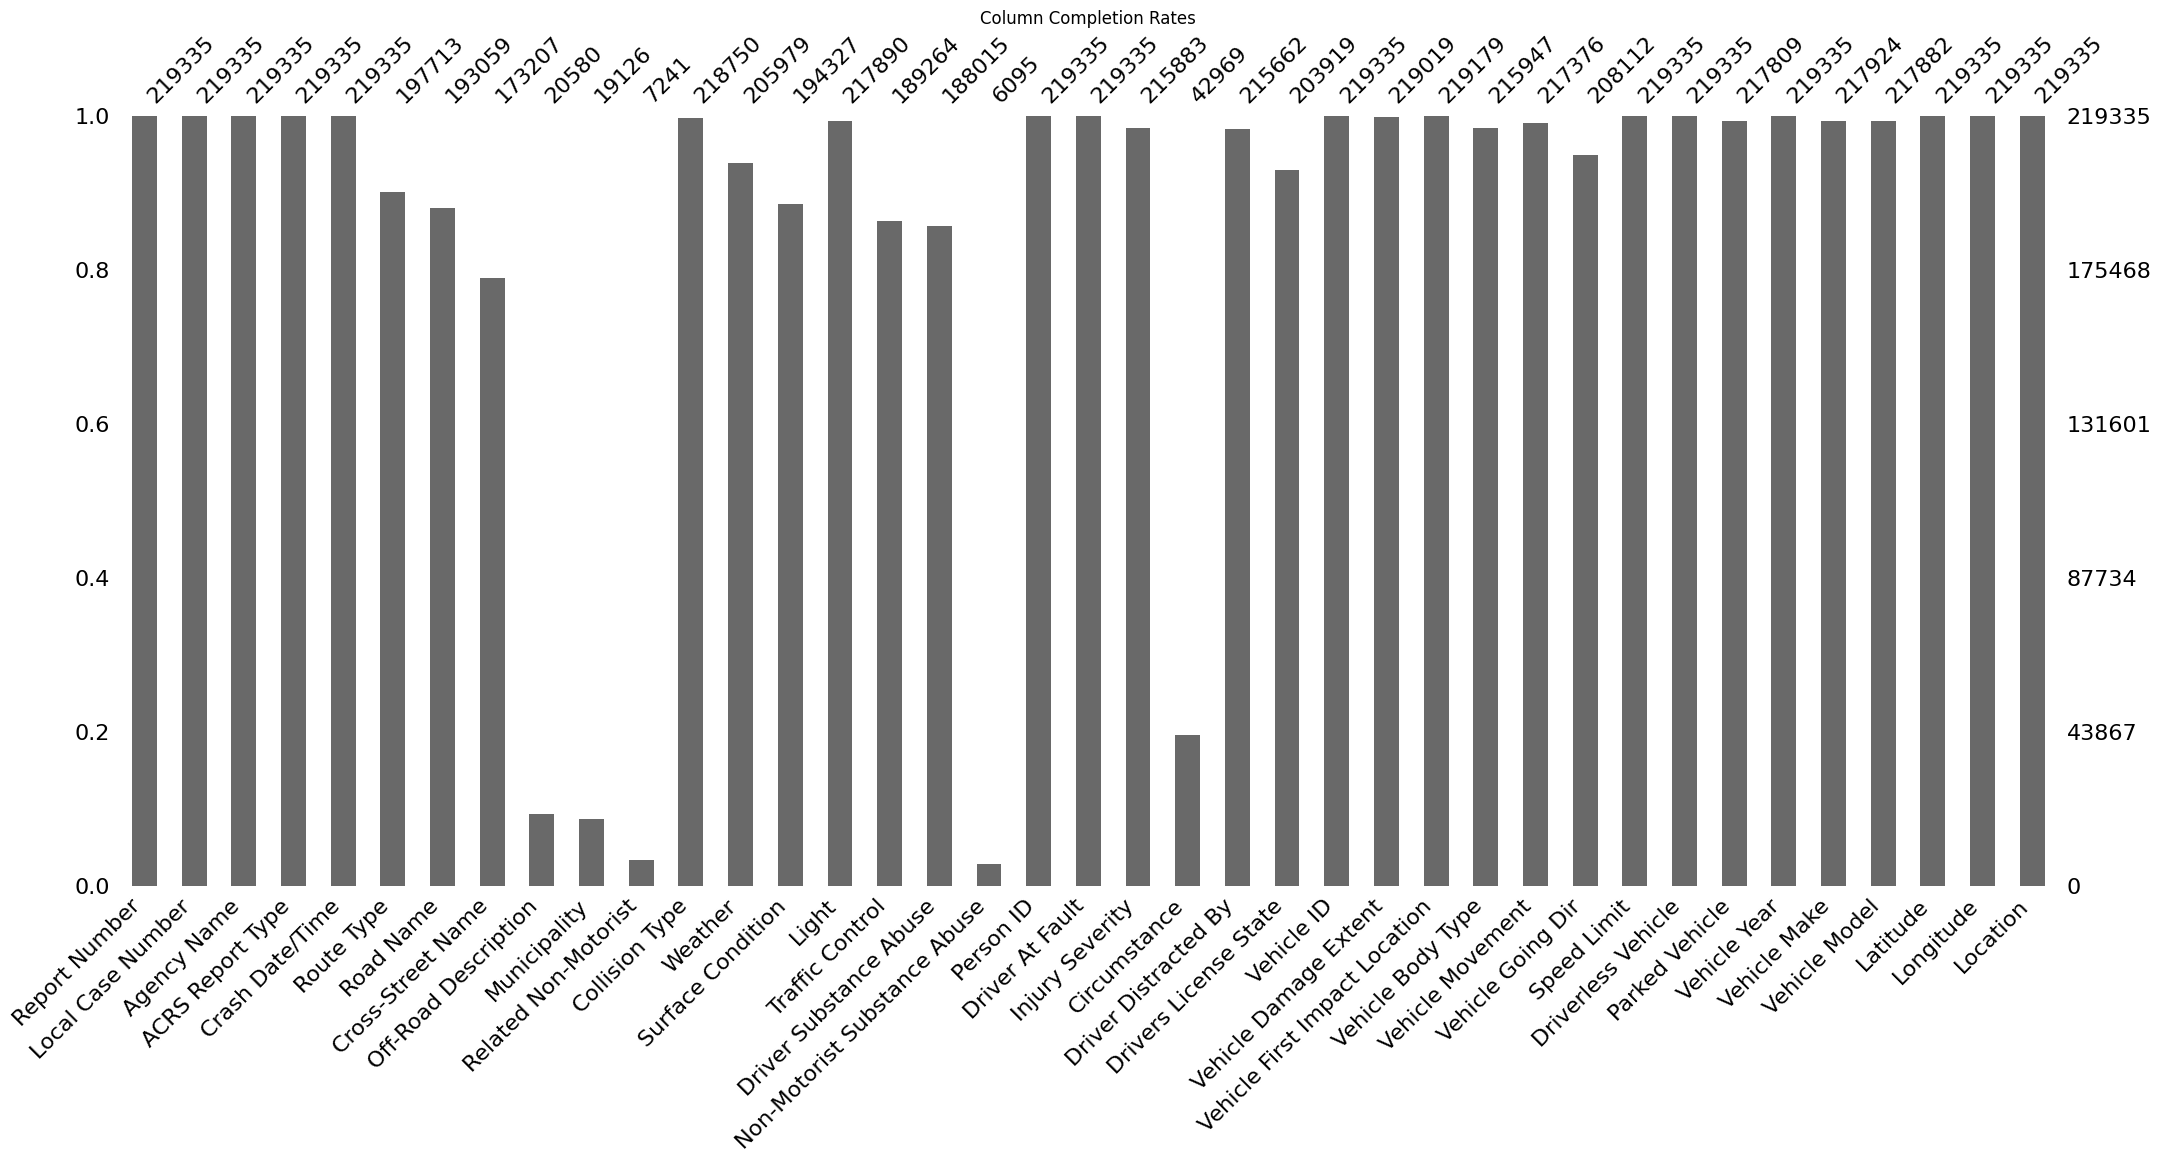

In [ ]:
# Bar plot of overall completion rates
plt.figure(figsize=(10, 5))
msno.bar(df_clean)
plt.title("Column Completion Rates")
plt.show()

In [ ]:
# Report missingness for every column
missing_report = pd.DataFrame({
    "Missing Count": df_clean.isna().sum(),
    "Missing Percent": df_clean.isna().mean().mul(100),
    "Non-Missing Count": df_clean.notna().sum()
})

missing_report = missing_report.sort_values(
    "Missing Percent",
    ascending=False
)

display(missing_report.round(2))

,Missing Count,Missing Percent,Non-Missing Count
Non-Motorist Substance Abuse,213240,97.22,6095
Related Non-Motorist,212094,96.70,7241
Municipality,200209,91.28,19126
Off-Road Description,198755,90.62,20580
Circumstance,176366,80.41,42969
Cross-Street Name,46128,21.03,173207
Driver Substance Abuse,31320,14.28,188015
Traffic Control,30071,13.71,189264
Road Name,26276,11.98,193059
Surface Condition,25008,11.40,194327


# Remove the requested columns and evaluate missingness
- removing `Cross-Street Name`, `Off-Road Description`, `Municipality`, `Related Non-Motorist`, `Non-Motorist Substance Abuse`, and `Circumstance` because over 50% of the data is missing

In [ ]:
# Columns explicitly requested for removal
requested_drop = [
    "Cross-Street Name",
    "Off-Road Description",
    "Municipality",
    "Related Non-Motorist",
    "Non-Motorist Substance Abuse",
    "Circumstance"
]

# Drop only columns that actually exist
requested_drop = [
    col for col in requested_drop
    if col in df_clean.columns
]

df_clean = df_clean.drop(columns=requested_drop)

print("Requested columns removed:", requested_drop)
print("Shape after requested drops:", df_clean.shape)

# Missingness after requested columns are removed
missing_pct = df_clean.isna().mean().mul(100).sort_values(
    ascending=False
)

print("\nRemaining columns with the most missing values:")
display(missing_pct.head(20).to_frame("Missing Percent"))

# Identify columns above the review threshold
MISSING_THRESHOLD = 80

high_missing_cols = missing_pct[
    missing_pct > MISSING_THRESHOLD
].index.tolist()

print(
    f"\nColumns with more than {MISSING_THRESHOLD}% missing:"
)
print(high_missing_cols)

# Review these columns before deciding whether to drop them.
# Do not automatically remove important predictors or identifiers.

Requested columns removed: ['Cross-Street Name', 'Off-Road Description', 'Municipality', 'Related Non-Motorist', 'Non-Motorist Substance Abuse', 'Circumstance']
Shape after requested drops: (219335, 33)

Remaining columns with the most missing values:


,Missing Percent
Driver Substance Abuse,14.279527
Traffic Control,13.710078
Road Name,11.979848
Surface Condition,11.401737
Route Type,9.857980
Drivers License State,7.028518
Weather,6.089315
Vehicle Going Dir,5.116830
Driver Distracted By,1.674607
Injury Severity,1.573848



Columns with more than 80% missing:
[]


# Recommended columns to keep:
- Driver Substance Abuse
- Driver Distracted By
- Weather
- Surface Condition
- Light
- Traffic Control
- Collision Type

# Standardize injury severity and categorical variables

In [ ]:
# Normalize labels for matching.
# Example: "Dark - Lighted" -> "dark lighted"
def normalize_label(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().casefold()
    value = re.sub(r"[^a-z0-9]+", " ", value)
    return re.sub(r"\s+", " ", value).strip()


# Normalize all categorical/text labels for consistent formatting
text_cols = df_clean.select_dtypes(
    include=["object", "string"]
).columns

for col in text_cols:
    df_clean[col] = df_clean[col].map(
        lambda x: re.sub(r"\s+", " ", x).strip()
        if isinstance(x, str)
        else x
    )

# Standardize injury severity
severity_map = {
    "no apparent injury": "No Apparent Injury",
    "possible injury": "Possible Injury",
    "suspected minor injury": "Suspected Minor Injury",
    "suspected serious injury": "Suspected Serious Injury",
    "fatal injury": "Fatal Injury"
}

df_clean["Injury Severity"] = (
    df_clean["Injury Severity"]
    .map(normalize_label)
    .map(severity_map)
)

print("Standardized injury severity:")
print(df_clean["Injury Severity"].value_counts(dropna=False))

Standardized injury severity:
Injury Severity
No Apparent Injury          177390
Possible Injury              20619
Suspected Minor Injury       15878
NaN                           3452
Suspected Serious Injury      1790
Fatal Injury                   206
Name: count, dtype: int64


## Standardize weather, surface, lighting, and traffic control

In [ ]:
def title_label(value):
    if pd.isna(value):
        return np.nan

    return normalize_label(value).title()


# Reusable mapping helper
def standardize_categories(series, mapping):
    normalized_mapping = {
        normalize_label(key): value
        for key, value in mapping.items()
    }

    normalized = series.map(normalize_label)

    return normalized.map(
        lambda x: normalized_mapping.get(x, title_label(x))
        if pd.notna(x)
        else np.nan
    )


# Weather
weather_map = {
    "clear": "Clear",
    "cloudy": "Cloudy",
    "rain": "Rain",
    "raining": "Rain",
    "Freezing Rain Or Freezing Drizzle": "Rain",
    "Blowing Snow": "Snow",
    "snow": "Snow",
    "sleet": "Sleet",
    "fog": "Fog",
    "foggy": "Fog",
    "Fog Smog Smoke": "Fog",
    "wintry mix": "Wintry Mix",
    "Severe Crosswinds": "Wind",
    "Severe Winds": "Wind",
    "wind": "Wind",
    "other": "Unknown",
    "unknown": "Unknown"
}

# Surface condition
surface_map = {
    "dry": "Dry",
    "wet": "Wet",
    "ice": "Ice",
    "ice frost": "Ice",
    "snow": "Snow",
    "slush": "Slush",
    "mud dirt gravel": "Mud/Dirt/Gravel",
    "water standing": "Wet",
    "Water Standing Moving": "Wet",
    "other": "Unknown",
    "unknown": "Unknown"
}

# Lighting
light_map = {
    "daylight": "Daylight",
    "dark lighted": "Dark - Lighted",
    "dark lights on": "Dark - Lighted",
    "dark not lighted": "Dark - Not Lighted",
    "dark no lights": "Dark - Not Lighted",
    "dark unknown lighting": "Dark - Unknown Lighting",
    "dawn": "Dawn",
    "dusk": "Dusk",
    "other": "Unknown",
    "unknown": "Unknown"
}

# Traffic control
traffic_map = {
    "no controls": "No Controls",
    "traffic signal": "Traffic Control Signal",
    "traffic control signal": "Traffic Control Signal",
    "stop sign": "Stop Sign",
    "yield sign": "Yield Sign",
    "flashing traffic signal": "Traffic Control Signal",
    "flashing traffic control signal": "Traffic Control Signal",
    "lane use control signal": "Lane Use Control Signal",
    "Pedestrian Crossing Sign": "Pedestrian Crossing",
    "Pedestrian Crossing": "Pedestrian Crossing",
    "person": "Person",
    "Other Signal": "Unknown",
    "other": "Unknown",
    "unknown": "Unknown"
}

category_mappings = {
    "Weather": weather_map,
    "Surface Condition": surface_map,
    "Light": light_map,
    "Traffic Control": traffic_map
}

for col, mapping in category_mappings.items():
    if col in df_clean.columns:
        df_clean[col] = standardize_categories(
            df_clean[col], mapping
        )

for col in category_mappings:
    if col in df_clean.columns:
        print(f"\n{col}:")
        print(df_clean[col].value_counts(dropna=False))


Weather:
Weather
Clear                     153916
Rain                       25387
Cloudy                     21535
NaN                        13356
Snow                        2108
Unknown                     1402
Fog                          798
Wintry Mix                   391
Sleet                        218
Wind                         190
Sleet Or Hail                 18
Blowing Sand Soil Dirt        16
Name: count, dtype: int64

Surface Condition:
Surface Condition
Dry                155492
Wet                 35027
NaN                 25008
Ice                  1320
Snow                 1294
Unknown               746
Slush                 353
Mud/Dirt/Gravel        56
Oil                    29
Sand                   10
Name: count, dtype: int64

Light:
Light
Daylight                   149315
Dark - Lighted              50275
Dark - Not Lighted           6560
Dusk                         4569
Dawn                         3937
Dark - Unknown Lighting      1842
NaN               

# Group collision types

In [ ]:
collision_group = {
    # Head-on collisions
    "head on": "Head-on",
    "front to front": "Head-on",
    "head on left turn": "Head-on",
    "head on involving left turn": "Head-on",

    # Rear-end collisions
    "same dir rear end": "Rear-end",
    "front to rear": "Rear-end",
    "rear end same direction": "Rear-end",
    "same dir rend left turn": "Rear-end",
    "same dir rend right turn": "Rear-end",

    # Sideswipes
    "same direction sideswipe": "Sideswipe (same direction)",
    "sideswipe same direction": "Sideswipe (same direction)",
    "same direction right turn sideswipe": "Sideswipe (same direction)",
    "same direction left turn sideswipe": "Sideswipe (same direction)",
    "opposite direction sideswipe": "Sideswipe (opposite direction)",
    "sideswipe opposite direction": "Sideswipe (opposite direction)",

    # Turning / opposing left turns
    "opposite dir both left turn": "Opposing left turns",
    "opposite direction both left turn collision": "Opposing left turns",
    "angle meets left head on": "Opposing left turns",
    "same direction left turn": "Turning (same direction)",
    "same direction right turn": "Turning (same direction)",
    "same dir both left turn": "Turning (same direction)",
    "same direction both left turn collision": "Turning (same direction)",

    # Angle collisions
    "straight movement angle": "Angle",
    "angle": "Angle",
    "rear to side": "Angle",
    "angle meets left turn": "Angle",
    "angle collision involving left turn": "Angle",
    "angle meets right turn": "Angle",
    "angle collision involving right turn": "Angle",
    "angle head on involving left turn": "Angle",

    # Other collision types
    "rear to rear": "Rear to Rear",
    "single vehicle": "Single vehicle",
    "other": "Unknown",
    "unknown": "Unknown"
}

# Normalize keys for reliable matching
collision_group_normalized = {
    normalize_label(key): value
    for key, value in collision_group.items()
}

# Keep the standardized raw category
df_clean["Collision Type"] = df_clean["Collision Type"].map(
    lambda x: title_label(x) if pd.notna(x) else np.nan
)

collision_raw = df_clean["Collision Type"].map(normalize_label)

df_clean["Collision Group"] = collision_raw.map(
    collision_group_normalized
)

# Inspect unmapped categories before deciding what to do
unmapped = df_clean.loc[
    collision_raw.notna() & df_clean["Collision Group"].isna(),
    "Collision Type"
].value_counts()

print("Unmapped collision types:")
print(unmapped)

print("\nCollision group counts:")
print(df_clean["Collision Group"].value_counts(dropna=False))

Unmapped collision types:
Series([], Name: count, dtype: int64)

Collision group counts:
Collision Group
Rear-end                          71180
Angle                             45673
Sideswipe (same direction)        23789
Unknown                           22838
Single vehicle                    21463
Head-on                           19354
Turning (same direction)           8266
Sideswipe (opposite direction)     4607
Opposing left turns                1022
NaN                                 585
Rear to Rear                        558
Name: count, dtype: int64


# Convert numeric fields and check invalid values

In [ ]:
numeric_cols = [
    "Speed Limit",
    "Vehicle Year",
    "Latitude",
    "Longitude"
]

for col in numeric_cols:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(
            df_clean[col], errors="coerce"
        )

# Flag impossible or suspicious values rather than deleting blindly
if "Speed Limit" in df_clean.columns:
    print("Speed limit distribution:")
    print(df_clean["Speed Limit"].describe())

    print(
        "Nonpositive speed limits:",
        (df_clean["Speed Limit"].notna() &
         (df_clean["Speed Limit"] <= 0)).sum()
    )

if "Vehicle Year" in df_clean.columns:
    print("Vehicle year distribution:")
    print(df_clean["Vehicle Year"].describe())

if {"Latitude", "Longitude"}.issubset(df_clean.columns):
    invalid_coordinates = (
        df_clean["Latitude"].notna()
        & ~df_clean["Latitude"].between(-90, 90)
    ) | (
        df_clean["Longitude"].notna()
        & ~df_clean["Longitude"].between(-180, 180)
    )

    print("Invalid coordinate rows:", invalid_coordinates.sum())

Speed limit distribution:
count    219335.000000
mean         32.016960
std          11.431505
min           0.000000
25%          25.000000
50%          35.000000
75%          40.000000
max          75.000000
Name: Speed Limit, dtype: float64
Nonpositive speed limits: 9498
Vehicle year distribution:
count    219335.000000
mean       1964.485764
std         345.355565
min           0.000000
25%        2007.000000
50%        2012.000000
75%        2016.000000
max        9999.000000
Name: Vehicle Year, dtype: float64
Invalid coordinate rows: 0


# Remove exact duplicates and filter to 2022–2025

In [ ]:
# Remove exact duplicate rows only
duplicates_before = df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates().copy()

print("Exact duplicates removed:", duplicates_before)
print("Shape after duplicate removal:", df_clean.shape)

# Exclude records with invalid/missing dates because the
# requested study period cannot be determined for those rows
valid_dates = df_clean["Crash Date/Time"].notna()

df_2022_2025 = df_clean.loc[
    valid_dates
    & df_clean["Crash Date/Time"].ge(
        pd.Timestamp("2022-01-01")
    )
    & df_clean["Crash Date/Time"].lt(
        pd.Timestamp("2026-01-01")
    )
].copy()

print("Shape after date filtering:", df_2022_2025.shape)
print(
    "Date range:",
    df_2022_2025["Crash Date/Time"].min(),
    "to",
    df_2022_2025["Crash Date/Time"].max()
)

print("\nRecords per year:")
print(
    df_2022_2025["Crash Date/Time"]
    .dt.year.value_counts()
    .sort_index()
)

Exact duplicates removed: 0
Shape after duplicate removal: (219335, 34)
Shape after date filtering: (73076, 34)
Date range: 2022-01-01 00:34:00 to 2025-12-31 22:50:00

Records per year:
Crash Date/Time
2022    17582
2023    18929
2024    18600
2025    17965
Name: count, dtype: int64


# Create time-based features

In [ ]:
dt = df_2022_2025["Crash Date/Time"]

# Calendar features
df_2022_2025["Crash Year"] = dt.dt.year
df_2022_2025["Crash Month"] = dt.dt.month
df_2022_2025["Crash Day"] = dt.dt.day
df_2022_2025["Crash Hour"] = dt.dt.hour

# Monday = 0, Sunday = 6
df_2022_2025["Crash Day of Week"] = dt.dt.dayofweek

# Weekend indicator
df_2022_2025["Is Weekend"] = (
    df_2022_2025["Crash Day of Week"] >= 5
).astype("int8")

# Time of day
def get_time_period(hour):
    if pd.isna(hour):
        return np.nan
    elif 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"

df_2022_2025["Crash Time Period"] = (
    df_2022_2025["Crash Hour"].map(get_time_period)
)

# Optional: rush-hour indicator, using a simple weekday definition
hour = df_2022_2025["Crash Hour"]
weekday = df_2022_2025["Crash Day of Week"] < 5

df_2022_2025["Is Weekday Rush Hour"] = (
    weekday
    & (
        hour.between(7, 9)
        | hour.between(16, 18)
    )
).astype("int8")

# Optional: season
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Fall", 10: "Fall", 11: "Fall"
}

df_2022_2025["Crash Season"] = (
    df_2022_2025["Crash Month"].map(season_map)
)

print("Time-based features created.")
display(
    df_2022_2025[
        [
            "Crash Date/Time",
            "Crash Year",
            "Crash Month",
            "Crash Hour",
            "Crash Day of Week",
            "Is Weekend",
            "Crash Time Period",
            "Is Weekday Rush Hour",
            "Crash Season"
        ]
    ].head()
)

Time-based features created.


,Crash Date/Time,Crash Year,Crash Month,Crash Hour,Crash Day of Week,Is Weekend,Crash Time Period,Is Weekday Rush Hour,Crash Season
10654,2025-12-31 22:50:00,2025,12,22,2,0,Night,0,Winter
10655,2025-12-31 21:54:00,2025,12,21,2,0,Night,0,Winter
10656,2025-12-31 21:54:00,2025,12,21,2,0,Night,0,Winter
10657,2025-12-31 21:40:00,2025,12,21,2,0,Night,0,Winter
10658,2025-12-31 21:40:00,2025,12,21,2,0,Night,0,Winter


# Reassess missing values and decide what to retain

In [ ]:
missing_after_filter = pd.DataFrame({
    "Missing Count": df_2022_2025.isna().sum(),
    "Missing Percent": (
        df_2022_2025.isna().mean() * 100
    ).round(2),
    "Unique Values": df_2022_2025.nunique(dropna=True)
}).sort_values("Missing Percent", ascending=False)

print("Missingness after filtering to 2022–2025:")
display(missing_after_filter)

# Save the missingness report for documentation
missing_after_filter.to_csv(
    "missingness_report_2022_2025.csv"
)

# Check the main predictors and target
important_cols = [
    "Injury Severity",
    "Collision Type",
    "Collision Group",
    "Weather",
    "Surface Condition",
    "Light",
    "Traffic Control",
    "Driver Substance Abuse",
    "Driver Distracted By",
    "Speed Limit",
    "Vehicle Body Type",
    "Crash Hour",
    "Crash Day of Week",
    "Crash Month"
]

important_cols = [
    col for col in important_cols
    if col in df_2022_2025.columns
]

display(missing_after_filter.loc[important_cols])

Missingness after filtering to 2022–2025:


,Missing Count,Missing Percent,Unique Values
Road Name,11364,15.55,3264
Traffic Control,7843,10.73,23
Surface Condition,7755,10.61,9
Route Type,7166,9.81,19
Drivers License State,7077,9.68,74
Vehicle Going Dir,7050,9.65,10
Driver Substance Abuse,6625,9.07,20
Weather,2701,3.70,10
Driver Distracted By,2681,3.67,24
Injury Severity,2493,3.41,5


,Missing Count,Missing Percent,Unique Values
Injury Severity,2493,3.41,5
Collision Type,132,0.18,25
Collision Group,132,0.18,10
Weather,2701,3.70,10
Surface Condition,7755,10.61,9
Light,291,0.40,7
Traffic Control,7843,10.73,23
Driver Substance Abuse,6625,9.07,20
Driver Distracted By,2681,3.67,24
Speed Limit,0,0.00,16


# Validate the cleaned dataset
- checks the target distribution, remaining duplicates, category mappings, and the date filter

In [ ]:
print("=" * 55)
print("FINAL CLEANING SUMMARY")
print("=" * 55)

print("\nDataset shape:", df_2022_2025.shape)

print("\nDate range:")
print(df_2022_2025["Crash Date/Time"].min())
print(df_2022_2025["Crash Date/Time"].max())

print("\nRecords per year:")
print(
    df_2022_2025["Crash Year"]
    .value_counts()
    .sort_index()
)

print("\nInjury severity distribution:")
print(
    df_2022_2025["Injury Severity"]
    .value_counts(dropna=False)
)

print("\nInjury severity proportions (%):")
print(
    df_2022_2025["Injury Severity"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

print("\nMissing target values:")
print(df_2022_2025["Injury Severity"].isna().sum())

print("\nExact duplicate rows:")
print(df_2022_2025.duplicated().sum())

print("\nCollision groups:")
print(
    df_2022_2025["Collision Group"]
    .value_counts(dropna=False)
)

print("\nMissing values in time-based features:")
time_features = [
    "Crash Year",
    "Crash Month",
    "Crash Hour",
    "Crash Day of Week",
    "Is Weekend",
    "Crash Time Period",
    "Is Weekday Rush Hour",
    "Crash Season"
]

print(df_2022_2025[time_features].isna().sum())

# Assertions for the study period
assert df_2022_2025["Crash Date/Time"].notna().all()
assert df_2022_2025["Crash Date/Time"].ge(
    pd.Timestamp("2022-01-01")
).all()
assert df_2022_2025["Crash Date/Time"].lt(
    pd.Timestamp("2026-01-01")
).all()

print("\nDate filter verification passed.")

FINAL CLEANING SUMMARY

Dataset shape: (73076, 43)

Date range:
2022-01-01 00:34:00
2025-12-31 22:50:00

Records per year:
Crash Year
2022    17582
2023    18929
2024    18600
2025    17965
Name: count, dtype: int64

Injury severity distribution:
Injury Severity
No Apparent Injury          58662
Possible Injury              6032
Suspected Minor Injury       5257
NaN                          2493
Suspected Serious Injury      557
Fatal Injury                   75
Name: count, dtype: int64

Injury severity proportions (%):
Injury Severity
No Apparent Injury          80.28
Possible Injury              8.25
Suspected Minor Injury       7.19
NaN                          3.41
Suspected Serious Injury     0.76
Fatal Injury                 0.10
Name: proportion, dtype: float64

Missing target values:
2493

Exact duplicate rows:
0

Collision groups:
Collision Group
Rear-end                          21749
Angle                             17064
Sideswipe (same direction)         9585
Single vehi

# Prepare the modeling dataset and save the output
- `df_2022_2025`: your cleaned study dataset, including rows with missing injury severity. Use it for descriptive analyses where appropriate.

- `df_model`: the subset with known injury severity, ready for a supervised classification workflow.
  - **NOTE**: `df_model` already removes rows with missing values in Injury Severity only

In [ ]:
# Keep the full cleaned study dataset for descriptive analysis
df_2022_2025.to_csv(
    "montgomery_crashes_cleaned_2022_2025.csv",
    index=False
)

# Create a labeled dataset for supervised modeling
df_model = df_2022_2025.loc[
    df_2022_2025["Injury Severity"].notna()
].copy()

print("Cleaned study dataset:", df_2022_2025.shape)
print("Labeled modeling dataset:", df_model.shape)
print(
    "Rows excluded due to missing target:",
    len(df_2022_2025) - len(df_model)
)

df_model.to_csv(
    "montgomery_crashes_modeling_2022_2025.csv",
    index=False
)

print("\nCleaned files saved successfully.")

Cleaned study dataset: (73076, 43)
Labeled modeling dataset: (70583, 43)
Rows excluded due to missing target: 2493

Cleaned files saved successfully.


# Verify the filtered dataset
- `df_2022_2025` becomes the main dataset for EDA and modeling.
  - **NOTE**: `df_2022_2025` STILL INCLUDES rows with missing values in injury severity

In [ ]:
# 1. Check dataset size
print("Filtered dataset shape:", df_2022_2025.shape)

# 2. Check date range and invalid dates
print("\nDate range:")
print(df_2022_2025["Crash Date/Time"].min())
print(df_2022_2025["Crash Date/Time"].max())

print(
    "Missing dates:",
    df_2022_2025["Crash Date/Time"].isna().sum()
)

# 3. Check records per year
print("\nRecords per year:")
print(
    df_2022_2025["Crash Date/Time"]
    .dt.year.value_counts()
    .sort_index()
)

# 4. Check injury severity
print("\nInjury severity distribution:")
print(
    df_2022_2025["Injury Severity"]
    .value_counts(dropna=False)
)

print(
    "\nMissing injury severity:",
    df_2022_2025["Injury Severity"].isna().sum()
)

# 5. Check duplicate rows
print(
    "\nDuplicate rows:",
    df_2022_2025.duplicated().sum()
)

# 6. Check collision groups
print("\nCollision groups:")
print(
    df_2022_2025["Collision Group"]
    .value_counts(dropna=False)
)

# 7. Verify time-based features
time_features = [
    "Crash Hour",
    "Crash Day of Week",
    "Crash Month"
]

print("\nTime feature missing values:")
print(df_2022_2025[time_features].isna().sum())

# 8. Confirm date filter
assert df_2022_2025["Crash Date/Time"].notna().all()
assert df_2022_2025["Crash Date/Time"].ge(
    pd.Timestamp("2022-01-01")
).all()
assert df_2022_2025["Crash Date/Time"].lt(
    pd.Timestamp("2026-01-01")
).all()

print("\nDate and target verification passed.")

Filtered dataset shape: (73076, 43)

Date range:
2022-01-01 00:34:00
2025-12-31 22:50:00
Missing dates: 0

Records per year:
Crash Date/Time
2022    17582
2023    18929
2024    18600
2025    17965
Name: count, dtype: int64

Injury severity distribution:
Injury Severity
No Apparent Injury          58662
Possible Injury              6032
Suspected Minor Injury       5257
NaN                          2493
Suspected Serious Injury      557
Fatal Injury                   75
Name: count, dtype: int64

Missing injury severity: 2493

Duplicate rows: 0

Collision groups:
Collision Group
Rear-end                          21749
Angle                             17064
Sideswipe (same direction)         9585
Single vehicle                     7572
Unknown                            6732
Head-on                            5728
Sideswipe (opposite direction)     1983
Turning (same direction)           1887
Rear to Rear                        442
Opposing left turns                 202
NaN            

# EDA (NO IMPUTATION HAS BEEN PERFORMED YET)

## Target Distribution from 2022-2025

Injury Severity
No Apparent Injury          58662
Possible Injury              6032
Suspected Minor Injury       5257
Suspected Serious Injury      557
Fatal Injury                   75
Name: count, dtype: int64

Percentages:
Injury Severity
No Apparent Injury          80.28
Possible Injury              8.25
Suspected Minor Injury       7.19
Suspected Serious Injury     0.76
Fatal Injury                 0.10
Name: count, dtype: float64


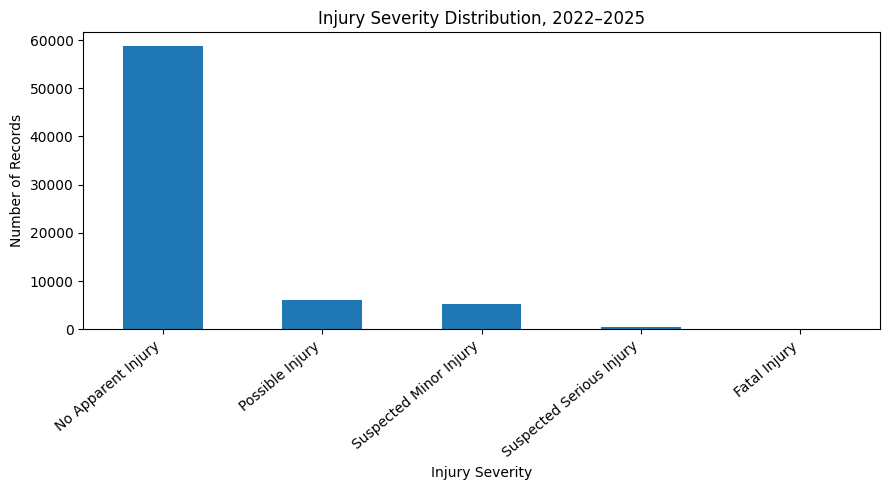

In [ ]:
target_counts = df_2022_2025["Injury Severity"].value_counts()

print(target_counts)
print("\nPercentages:")
print(
    (target_counts / len(df_2022_2025) * 100).round(2)
)

target_counts.plot(kind="bar", figsize=(9, 5))
plt.title("Injury Severity Distribution, 2022–2025")
plt.xlabel("Injury Severity")
plt.ylabel("Number of Records")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

## Record how many target labels are missing

In [ ]:
# Record how many target labels are missing
missing_target = df_2022_2025["Injury Severity"].isna().sum()

print("Rows with missing Injury Severity:", missing_target)

Rows with missing Injury Severity: 2493


## Examine missing values
- **What to look for**: Which potentially useful features have lots of missing values? Missing values can limit the information available for analysis and modeling. Don't automatically delete every column with missing data; decide based on its usefulness and how much information is missing.

,Missing Count,Missing Percent
Road Name,11364,15.55
Traffic Control,7843,10.73
Surface Condition,7755,10.61
Route Type,7166,9.81
Drivers License State,7077,9.68
Vehicle Going Dir,7050,9.65
Driver Substance Abuse,6625,9.07
Weather,2701,3.70
Driver Distracted By,2681,3.67
Injury Severity,2493,3.41


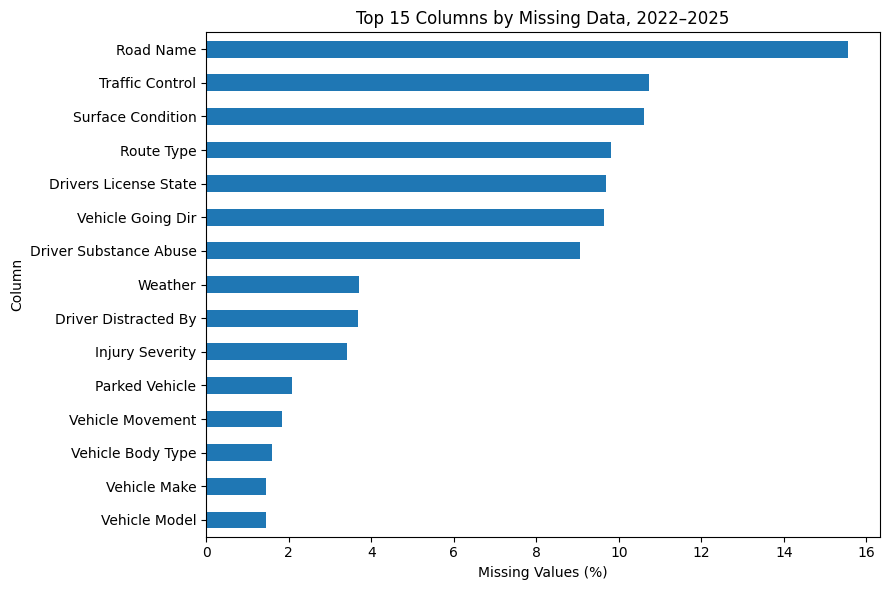

In [ ]:
# Missing values in the filtered EDA dataset
missing_summary = pd.DataFrame({
    "Missing Count": df_2022_2025.isna().sum(),
    "Missing Percent": (
        df_2022_2025.isna().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    "Missing Percent", ascending=False
)

display(missing_summary.head(20))

# Visualize the 15 columns with the most missing data
top_missing = missing_summary[
    missing_summary["Missing Count"] > 0
].head(15)

top_missing["Missing Percent"].sort_values().plot(
    kind="barh", figsize=(9, 6)
)

plt.title("Top 15 Columns by Missing Data, 2022–2025")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

# Compare injury severity across collision types
- **What to look for**: Are serious or fatal injuries proportionally more common in some collision groups than others? Which groups mostly contain no-apparent-injury records?

Injury Severity,No Apparent Injury,Possible Injury,Suspected Minor Injury,Suspected Serious Injury,Fatal Injury
Collision Group,,,,,
Angle,77.52,11.17,10.16,1.05,0.11
Head-on,71.93,13.52,12.07,2.20,0.28
Opposing left turns,77.23,13.37,7.92,0.99,0.50
Rear to Rear,89.94,3.63,6.42,0.00,0.00
Rear-end,84.36,8.97,6.37,0.29,0.01
Sideswipe (opposite direction),85.90,6.57,6.73,0.80,0.00
Sideswipe (same direction),93.34,3.51,2.97,0.15,0.02
Single vehicle,81.33,7.89,8.57,1.76,0.45
Turning (same direction),90.78,5.30,3.60,0.26,0.05


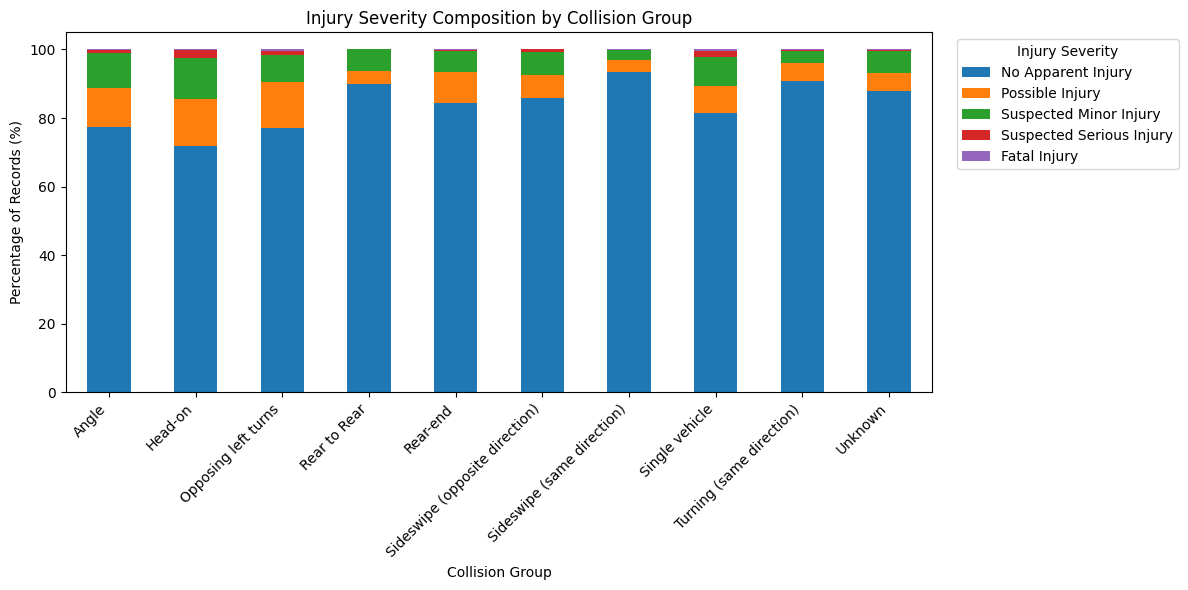

In [ ]:
## Compare injury severity across collision types
severity_order = [
    "No Apparent Injury",
    "Possible Injury",
    "Suspected Minor Injury",
    "Suspected Serious Injury",
    "Fatal Injury"
]

collision_table = pd.crosstab(
    df_2022_2025["Collision Group"],
    df_2022_2025["Injury Severity"],
    normalize="index"
) * 100

collision_table = collision_table.reindex(
    columns=severity_order, fill_value=0
)

display(collision_table.round(2))

collision_table.plot(
    kind="bar", stacked=True, figsize=(12, 6)
)

plt.title("Injury Severity Composition by Collision Group")
plt.xlabel("Collision Group")
plt.ylabel("Percentage of Records (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(
    title="Injury Severity",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

# Explore weather, lighting, road surface, and traffic control
- **What to look for**: Do the severity distributions differ across weather conditions, light conditions, road surfaces, or traffic controls?

- Be cautious with rare categories. For example, a category with very few records may have a high fatal-injury percentage simply because its sample size is small.


Injury severity by Weather (%)


Injury Severity,No Apparent Injury,Possible Injury,Suspected Minor Injury,Suspected Serious Injury,Fatal Injury
Weather,,,,,
Clear,83.19,8.33,7.55,0.81,0.11
Cloudy,81.29,10.20,7.46,0.88,0.16
Fog,86.46,5.24,7.42,0.87,0.00
Rain,82.95,8.78,7.56,0.64,0.06
Sleet,85.71,0.00,14.29,0.00,0.00
Sleet Or Hail,92.31,0.00,7.69,0.00,0.00
Snow,82.60,9.84,7.21,0.35,0.00
Unknown,91.16,5.05,2.78,1.01,0.00
Wind,82.14,7.14,8.93,1.79,0.00


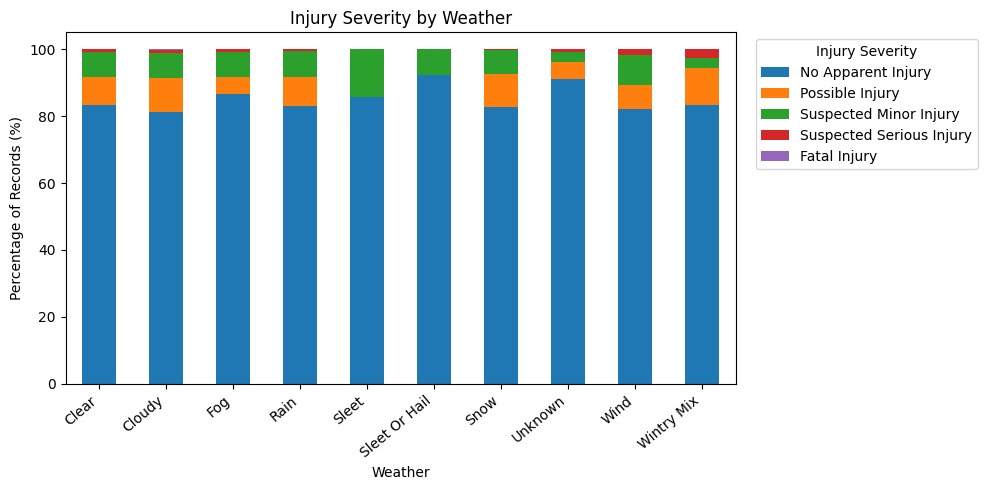


Injury severity by Light (%)


Injury Severity,No Apparent Injury,Possible Injury,Suspected Minor Injury,Suspected Serious Injury,Fatal Injury
Light,,,,,
Dark - Lighted,83.18,7.68,8.04,0.97,0.13
Dark - Not Lighted,81.06,8.97,8.38,1.28,0.32
Dark - Unknown Lighting,87.64,7.53,3.47,0.77,0.58
Dawn,79.45,10.85,8.36,0.98,0.36
Daylight,83.11,8.86,7.27,0.69,0.07
Dusk,83.91,8.09,6.47,1.28,0.26
Unknown,91.33,2.55,5.87,0.26,0.00


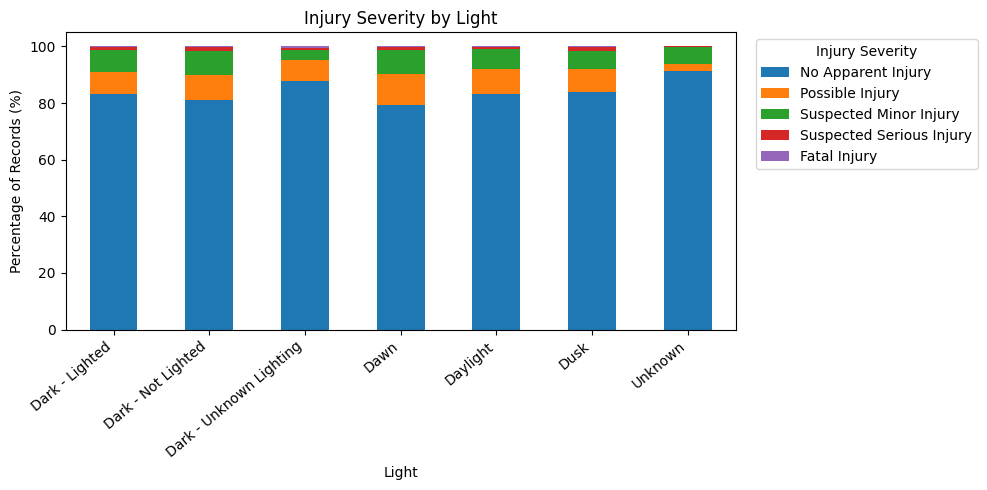


Injury severity by Surface Condition (%)


Injury Severity,No Apparent Injury,Possible Injury,Suspected Minor Injury,Suspected Serious Injury,Fatal Injury
Surface Condition,,,,,
Dry,82.03,9.00,7.98,0.86,0.13
Ice,80.91,11.97,6.47,0.32,0.32
Mud/Dirt/Gravel,76.92,7.69,15.38,0.00,0.00
Oil,66.67,16.67,16.67,0.00,0.00
Sand,100.00,0.00,0.00,0.00,0.00
Slush,76.84,12.63,10.53,0.00,0.00
Snow,84.19,9.35,5.48,0.97,0.00
Unknown,91.01,3.93,4.49,0.56,0.00
Wet,81.95,9.24,7.93,0.79,0.08


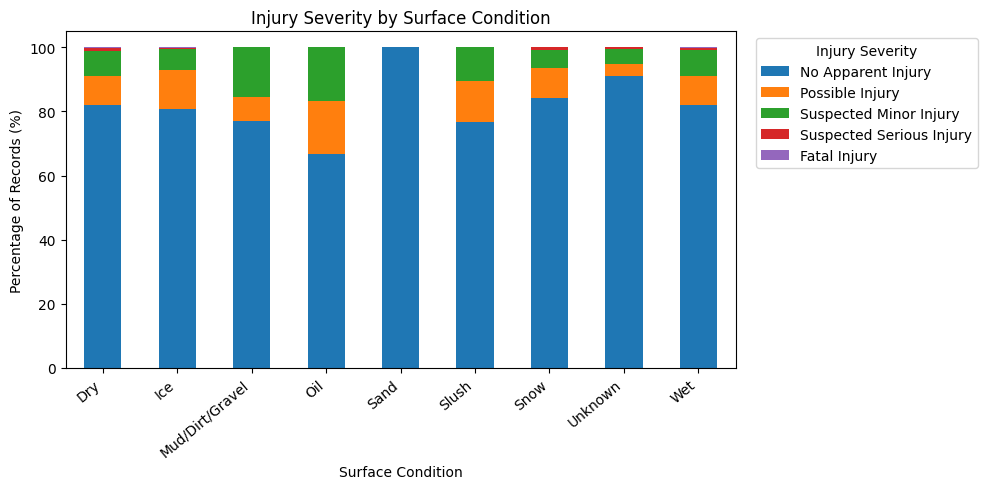


Injury severity by Traffic Control (%)


Injury Severity,No Apparent Injury,Possible Injury,Suspected Minor Injury,Suspected Serious Injury,Fatal Injury
Traffic Control,,,,,
Intersection Ahead Warning Sign,88.64,4.55,4.55,2.27,0.00
Lane Use Control Signal,86.43,6.33,7.24,0.00,0.00
No Controls,83.99,7.75,7.18,0.96,0.12
Other Pavement Marking Excluding Edgelines Centerlines Or Lane Lines,89.42,0.96,9.62,0.00,0.00
Pedestrian Crossing,82.45,7.84,9.40,0.00,0.31
Person,94.03,2.99,2.99,0.00,0.00
Stop Sign,82.14,9.83,7.32,0.61,0.10
Traffic Control Signal,80.18,10.14,8.85,0.75,0.08
Unknown,88.72,6.96,3.40,0.77,0.15


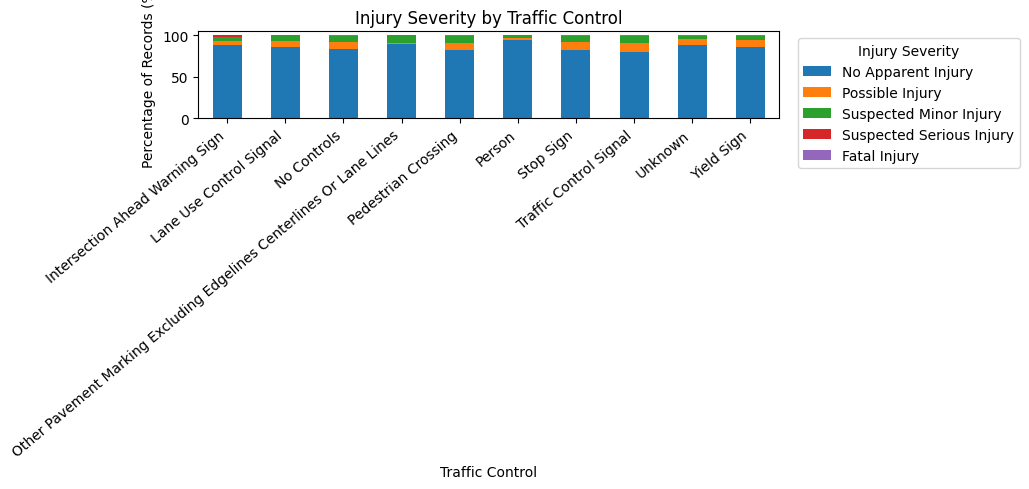

In [ ]:
environment_features = [
    "Weather",
    "Light",
    "Surface Condition",
    "Traffic Control"
]

for feature in environment_features:
    if feature not in df_2022_2025.columns:
        print(f"Skipping {feature}: column not found.")
        continue

    # Show the 10 most frequent categories
    top_categories = (
        df_2022_2025[feature]
        .value_counts()
        .head(10)
        .index
    )

    subset = df_2022_2025[
        df_2022_2025[feature].isin(top_categories)
    ]

    table = pd.crosstab(
        subset[feature],
        subset["Injury Severity"],
        normalize="index"
    ) * 100

    table = table.reindex(
        columns=severity_order, fill_value=0
    )

    print(f"\nInjury severity by {feature} (%)")
    display(table.round(2))

    table.plot(
        kind="bar", stacked=True, figsize=(10, 5)
    )
    plt.title(f"Injury Severity by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Percentage of Records (%)")
    plt.xticks(rotation=40, ha="right")
    plt.legend(
        title="Injury Severity",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )
    plt.tight_layout()
    plt.show()

# Examine numerical features (speed limit and vehicle year)
- **What to look for**: Are speed limits higher in certain severity groups? Do vehicle years differ substantially?

- Remember that Vehicle Year describes the vehicle's model year, not the crash year. Also, a boxplot shows distributions, not proof that a characteristic caused an injury.

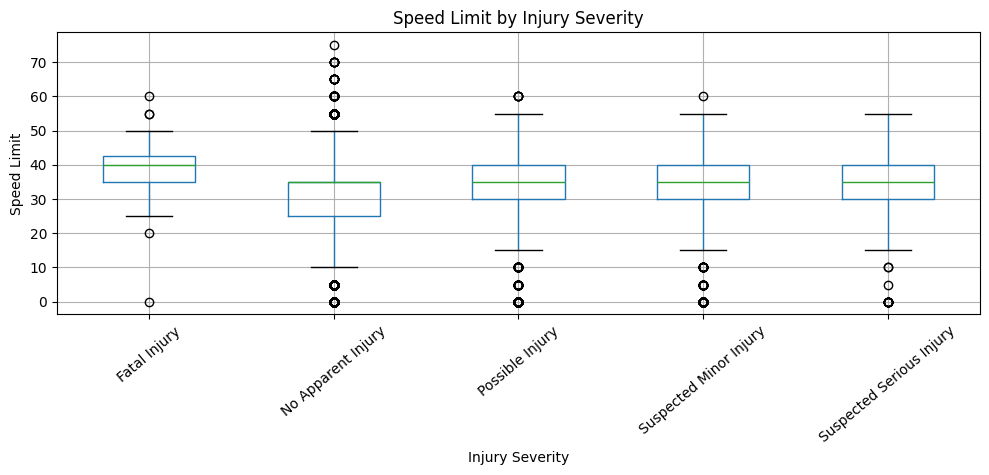


Summary statistics for Speed Limit:


,count,mean,std,min,25%,50%,75%,max
Injury Severity,,,,,,,,
Fatal Injury,75.0,37.93,8.89,0.0,35.0,40.0,42.5,60.0
No Apparent Injury,58662.0,30.73,11.81,0.0,25.0,35.0,35.0,75.0
Possible Injury,6032.0,34.16,9.38,0.0,30.0,35.0,40.0,60.0
Suspected Minor Injury,5257.0,34.15,9.28,0.0,30.0,35.0,40.0,60.0
Suspected Serious Injury,557.0,34.67,9.42,0.0,30.0,35.0,40.0,55.0


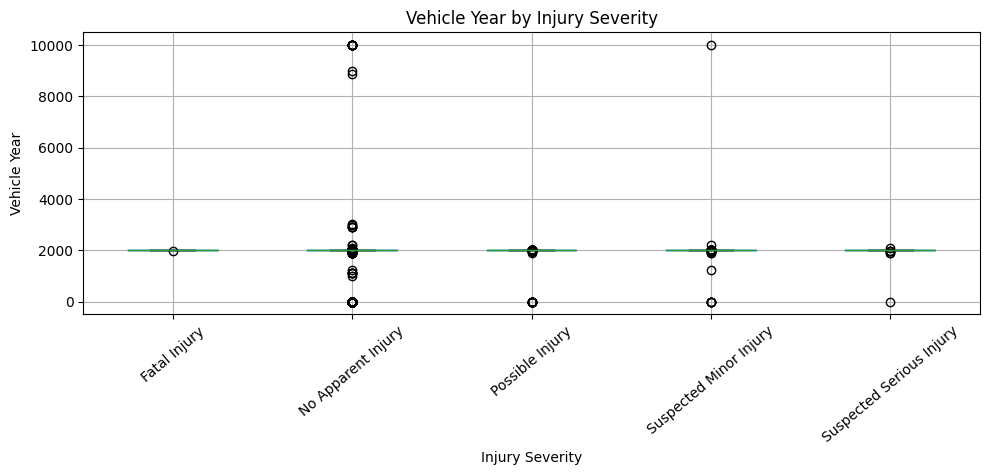


Summary statistics for Vehicle Year:


,count,mean,std,min,25%,50%,75%,max
Injury Severity,,,,,,,,
Fatal Injury,75.0,2012.39,7.64,1977.0,2007.0,2013.0,2018.0,2024.0
No Apparent Injury,58662.0,1974.38,313.12,0.0,2010.0,2016.0,2019.0,9999.0
Possible Injury,6032.0,2007.13,121.61,0.0,2011.0,2015.0,2019.0,2026.0
Suspected Minor Injury,5257.0,2014.12,127.12,0.0,2011.0,2016.0,2019.0,9999.0
Suspected Serious Injury,557.0,2009.26,85.97,0.0,2008.0,2014.0,2019.0,2109.0


In [ ]:
numeric_features = ["Speed Limit", "Vehicle Year"]

for feature in numeric_features:
    if feature not in df_2022_2025.columns:
        print(f"Skipping {feature}: column not found.")
        continue

    df_2022_2025.boxplot(
        column=feature,
        by="Injury Severity",
        figsize=(10, 5),
        rot=40
    )

    plt.title(f"{feature} by Injury Severity")
    plt.suptitle("")
    plt.xlabel("Injury Severity")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()

    print(f"\nSummary statistics for {feature}:")
    display(
        df_2022_2025.groupby("Injury Severity")[feature]
        .describe()
        .round(2)
    )

# Explore Crash timing ( Using Crash Hour, Crash Day of Week, and Crash Month)
- **What to look for**: Do the proportions of serious injuries differ by hour or weekday? Are there noticeable patterns during nighttime or weekends?

- These are descriptive patterns in reported crashes. They do not tell you the risk per trip or per mile, because the amount of traffic at each time is not accounted for.

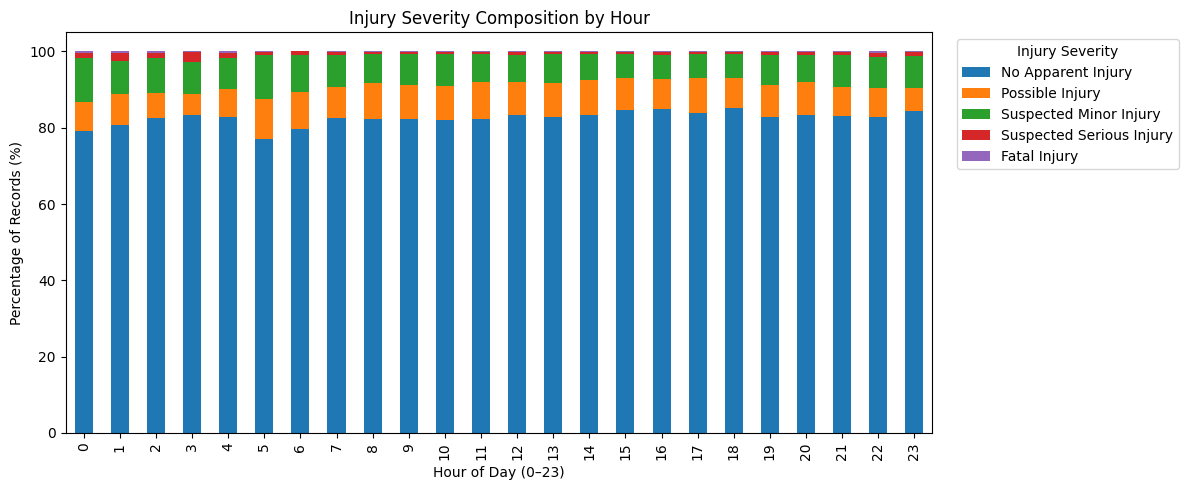

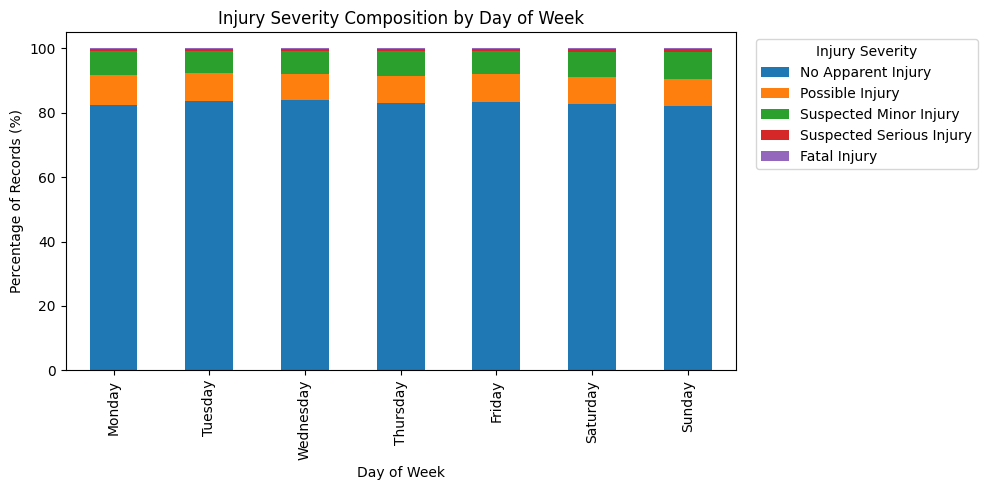

In [ ]:
# Translate weekday numbers into readable names
day_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

# Injury severity composition by hour
hour_table = pd.crosstab(
    df_2022_2025["Crash Hour"],
    df_2022_2025["Injury Severity"],
    normalize="index"
) * 100

hour_table = hour_table.reindex(
    columns=severity_order, fill_value=0
)

hour_table.plot(
    kind="bar", stacked=True, figsize=(12, 5)
)

plt.title("Injury Severity Composition by Hour")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Percentage of Records (%)")
plt.legend(
    title="Injury Severity",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

# Injury severity composition by weekday
weekday_data = df_2022_2025.copy()
weekday_data["Day Name"] = (
    weekday_data["Crash Day of Week"].map(day_names)
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_table = pd.crosstab(
    weekday_data["Day Name"],
    weekday_data["Injury Severity"],
    normalize="index"
) * 100

weekday_table = weekday_table.reindex(
    index=weekday_order,
    columns=severity_order,
    fill_value=0
)

weekday_table.plot(
    kind="bar", stacked=True, figsize=(10, 5)
)

plt.title("Injury Severity Composition by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Percentage of Records (%)")
plt.legend(
    title="Injury Severity",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

# Heatmap using numerical features

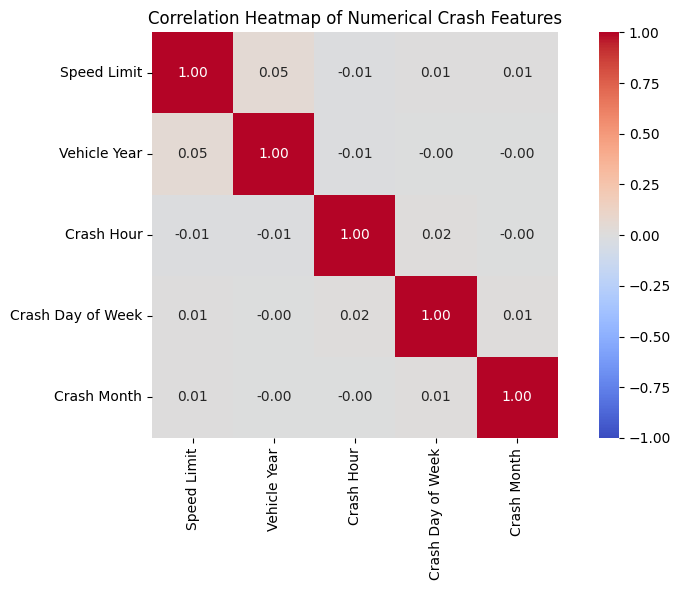

In [ ]:
# Select numerical features relevant to crash characteristics
numeric_features = [
    "Speed Limit",
    "Vehicle Year",
    "Crash Hour",
    "Crash Day of Week",
    "Crash Month"
]

# Keep only columns that exist in the dataset
numeric_features = [
    col for col in numeric_features
    if col in df_2022_2025.columns
]

# Calculate correlations
corr_matrix = df_2022_2025[numeric_features].corr()

# Plot heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f",
    square=True
)

plt.title("Correlation Heatmap of Numerical Crash Features")
plt.tight_layout()
plt.show()

# Heatmap Injury severity by feature

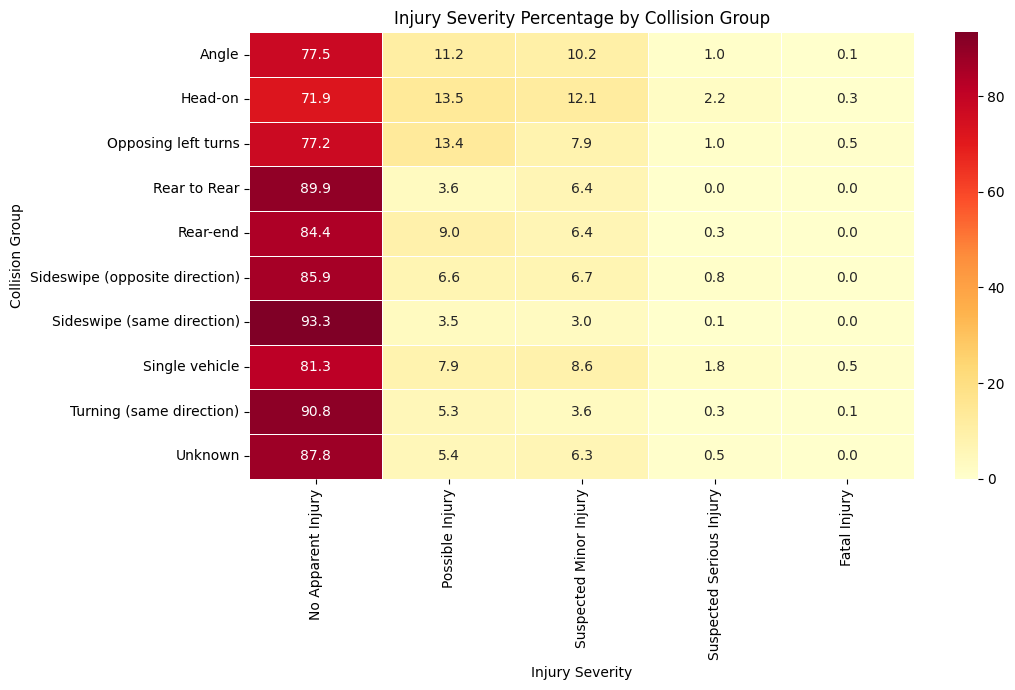

In [ ]:
severity_order = [
    "No Apparent Injury",
    "Possible Injury",
    "Suspected Minor Injury",
    "Suspected Serious Injury",
    "Fatal Injury"
]

severity_heatmap = pd.crosstab(
    df_2022_2025["Collision Group"],
    df_2022_2025["Injury Severity"],
    normalize="index"
) * 100

severity_heatmap = severity_heatmap.reindex(
    columns=severity_order, fill_value=0
)

plt.figure(figsize=(11, 7))

sns.heatmap(
    severity_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Injury Severity Percentage by Collision Group")
plt.xlabel("Injury Severity")
plt.ylabel("Collision Group")
plt.tight_layout()
plt.show()


# Defining Target and predictors

In [ ]:
# Define the target
target = "Injury Severity"

# Start with crash characteristics that could be useful
candidate_features = [
    "Collision Group",
    "Weather",
    "Surface Condition",
    "Light",
    "Traffic Control",
    "Speed Limit",
    "Vehicle Body Type",
    "Vehicle Movement",
    "Vehicle Going Dir",
    "Route Type",
    "Municipality",
    "Crash Hour",
    "Crash Day of Week",
    "Crash Month"
]

# Keep only columns that exist
features = [
    col for col in candidate_features
    if col in df_2022_2025.columns
]

# Create the modeling dataset
df_model = df_2022_2025[features + [target]].copy()

X = df_model[features]

X = df_model[features].copy()

# Convert pandas string columns to standard object columns
# and represent missing values as np.nan
for col in X.select_dtypes(
    include=["object", "category", "string"]
).columns:
    X[col] = X[col].astype(object)
    X[col] = X[col].where(X[col].notna(), np.nan)

y = df_model[target]

y = df_model[target]

print("Number of records:", len(df_model))
print("Number of predictors:", len(features))
print("Predictors:", features)
print("\nTarget distribution:")
display(y.value_counts().to_frame("Count"))


Number of records: 73076
Number of predictors: 13
Predictors: ['Collision Group', 'Weather', 'Surface Condition', 'Light', 'Traffic Control', 'Speed Limit', 'Vehicle Body Type', 'Vehicle Movement', 'Vehicle Going Dir', 'Route Type', 'Crash Hour', 'Crash Day of Week', 'Crash Month']

Target distribution:


,Count
Injury Severity,
No Apparent Injury,58662
Possible Injury,6032
Suspected Minor Injury,5257
Suspected Serious Injury,557
Fatal Injury,75


# **EDA Imputation**

Prepare the modeling dataset

In [ ]:
# Define target variable
target = "Injury Severity"

# Select candidate predictor features
candidate_features = [
    "Collision Group",
    "Weather",
    "Surface Condition",
    "Light",
    "Traffic Control",
    "Speed Limit",
    "Vehicle Body Type",
    "Vehicle Movement",
    "Vehicle Going Dir",
    "Route Type",
    "Crash Hour",
    "Crash Day of Week",
    "Crash Month"
]

# Keep only features that exist in the dataset
features = [
    col for col in candidate_features
    if col in df_2022_2025.columns
]

# Create a separate modeling dataset
# Remove rows with missing target values only
df_model = df_2022_2025.loc[
    df_2022_2025[target].notna()
].copy()

# Standardize target text
df_model[target] = df_model[target].astype(str).str.strip()

# Keep only valid injury severity categories
valid_severity = [
    "No Apparent Injury",
    "Possible Injury",
    "Suspected Minor Injury",
    "Suspected Serious Injury",
    "Fatal Injury"
]

df_model = df_model.loc[
    df_model[target].isin(valid_severity)
].copy()

# Create predictor matrix and target vector
X = df_model[features].copy()
y = df_model[target].copy()

# Display dataset information
print("Original cleaned dataset:", df_2022_2025.shape)
print("Modeling dataset:", df_model.shape)
print("Number of predictor features:", len(features))

print("\nSelected features:")
print(features)

print("\nInjury Severity counts:")
print(y.value_counts())

print("\nInjury Severity percentages:")
print((y.value_counts(normalize=True) * 100).round(2))


Original cleaned dataset: (73076, 43)
Modeling dataset: (70583, 43)
Number of predictor features: 13

Selected features:
['Collision Group', 'Weather', 'Surface Condition', 'Light', 'Traffic Control', 'Speed Limit', 'Vehicle Body Type', 'Vehicle Movement', 'Vehicle Going Dir', 'Route Type', 'Crash Hour', 'Crash Day of Week', 'Crash Month']

Injury Severity counts:
Injury Severity
No Apparent Injury          58662
Possible Injury              6032
Suspected Minor Injury       5257
Suspected Serious Injury      557
Fatal Injury                   75
Name: count, dtype: int64

Injury Severity percentages:
Injury Severity
No Apparent Injury          83.11
Possible Injury              8.55
Suspected Minor Injury       7.45
Suspected Serious Injury     0.79
Fatal Injury                 0.11
Name: proportion, dtype: float64


Rows before target filtering: 73076
Rows after target filtering: 70583
Rows removed: 2493


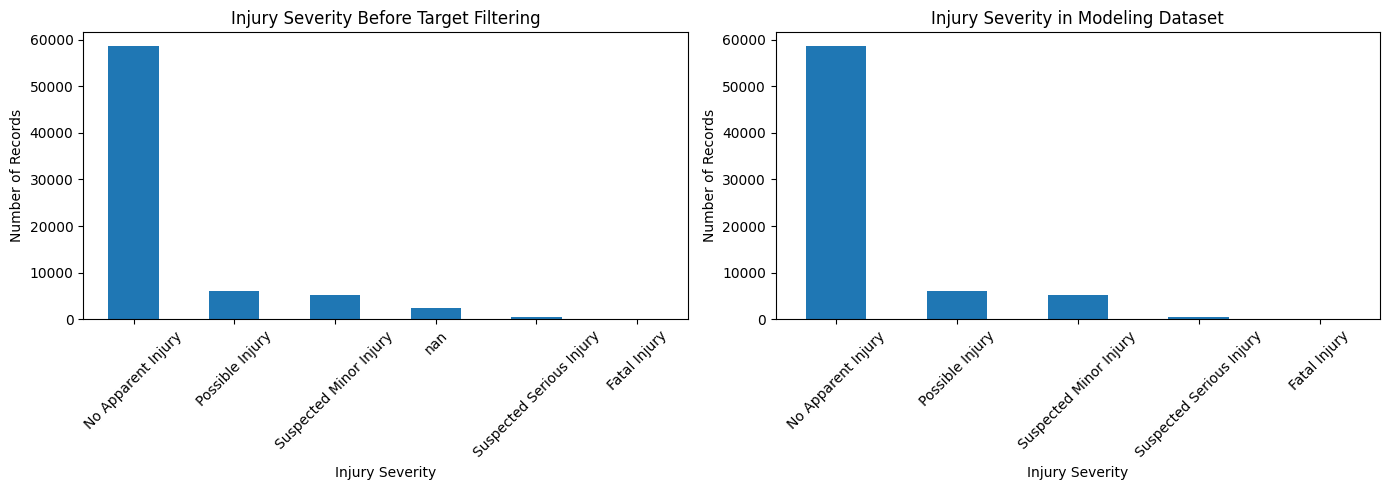


Missing predictor values in df_model:
Traffic Control      7199
Surface Condition    7049
Vehicle Going Dir    6718
Route Type           6515
Weather              2701
Vehicle Movement      908
Vehicle Body Type     666
Light                 291
Collision Group       132
Speed Limit             0
Crash Hour              0
Crash Day of Week       0
Crash Month             0
dtype: int64


In [ ]:
# Compare dataset sizes
print("Rows before target filtering:", len(df_2022_2025))
print("Rows after target filtering:", len(df_model))
print("Rows removed:", len(df_2022_2025) - len(df_model))

# Compare injury severity distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_2022_2025[target].value_counts(dropna=False).plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Injury Severity Before Target Filtering")
axes[0].set_xlabel("Injury Severity")
axes[0].set_ylabel("Number of Records")
axes[0].tick_params(axis="x", rotation=45)

df_model[target].value_counts().plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Injury Severity in Modeling Dataset")
axes[1].set_xlabel("Injury Severity")
axes[1].set_ylabel("Number of Records")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# Check missing predictor values
print("\nMissing predictor values in df_model:")
print(
    df_model[features]
    .isna()
    .sum()
    .sort_values(ascending=False)
)


Split training and testing data
- New split is now (2022-2024) train/(2025) test

In [ ]:
# Split by crash year
train_df = df_model[
    df_model["Crash Year"].between(2022, 2024)
].copy()

test_df = df_model[
    df_model["Crash Year"] == 2025
].copy()

# Create training and testing predictors
X_train = train_df[features].copy()
X_test = test_df[features].copy()

# Create training and testing targets
y_train = train_df[target].copy()
y_test = test_df[target].copy()

# Check split sizes
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining severity distribution:")
print(y_train.value_counts())

print("\nTesting severity distribution:")
print(y_test.value_counts())

# Check for empty splits
assert len(X_train) > 0, "Training dataset is empty."
assert len(X_test) > 0, "Testing dataset is empty."


Training records: 53968
Testing records: 16615

Training severity distribution:
Injury Severity
No Apparent Injury          44904
Possible Injury              4789
Suspected Minor Injury       3795
Suspected Serious Injury      424
Fatal Injury                   56
Name: count, dtype: int64

Testing severity distribution:
Injury Severity
No Apparent Injury          13758
Suspected Minor Injury       1462
Possible Injury              1243
Suspected Serious Injury      133
Fatal Injury                   19
Name: count, dtype: int64


Separate numeric and categorical features

In [ ]:
# Identify numeric features
numeric_features = [
    col for col in [
        "Speed Limit",
        "Crash Hour",
        "Crash Day of Week",
        "Crash Month"
    ]
    if col in features
]

# All remaining features are categorical
categorical_features = [
    col for col in features
    if col not in numeric_features
]

# Convert numeric columns safely
for col in numeric_features:
    X_train[col] = pd.to_numeric(
        X_train[col], errors="coerce"
    )
    X_test[col] = pd.to_numeric(
        X_test[col], errors="coerce"
    )

# Ensure categorical values are handled consistently
for col in categorical_features:
    X_train[col] = X_train[col].astype("object")
    X_test[col] = X_test[col].astype("object")

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['Speed Limit', 'Crash Hour', 'Crash Day of Week', 'Crash Month']
Categorical features: ['Collision Group', 'Weather', 'Surface Condition', 'Light', 'Traffic Control', 'Vehicle Body Type', 'Vehicle Movement', 'Vehicle Going Dir', 'Route Type']


Imputation and preprocessing pipeline

In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numeric preprocessing:
# 1. Fill missing values with the median
# 2. Standardize numeric features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing:
# 1. Fill missing values with the most frequent category
# 2. Convert categories into numerical indicator columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Imputation and preprocessing pipeline created.")


Imputation and preprocessing pipeline created.


Fit the baseline model and generate predictions
- baseline is logistic regression

In [ ]:

from sklearn.linear_model import LogisticRegression

# Create the complete modeling pipeline
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# Fit model:
# Imputation and preprocessing are learned from training data only
baseline_model.fit(X_train, y_train)

# Generate predictions for 2025
y_pred = baseline_model.predict(X_test)

print("Model fitted successfully.")
print("Predictions generated:", len(y_pred))


Model fitted successfully.
Predictions generated: 16615


Accuracy: 0.3772
Balanced Accuracy: 0.3246
Macro F1 Score: 0.1744

Classification Report:
                          precision    recall  f1-score   support

      No Apparent Injury       0.91      0.39      0.55     13758
         Possible Injury       0.11      0.07      0.09      1243
  Suspected Minor Injury       0.11      0.53      0.18      1462
Suspected Serious Injury       0.02      0.37      0.04       133
            Fatal Injury       0.01      0.26      0.01        19

                accuracy                           0.38     16615
               macro avg       0.23      0.32      0.17     16615
            weighted avg       0.78      0.38      0.47     16615



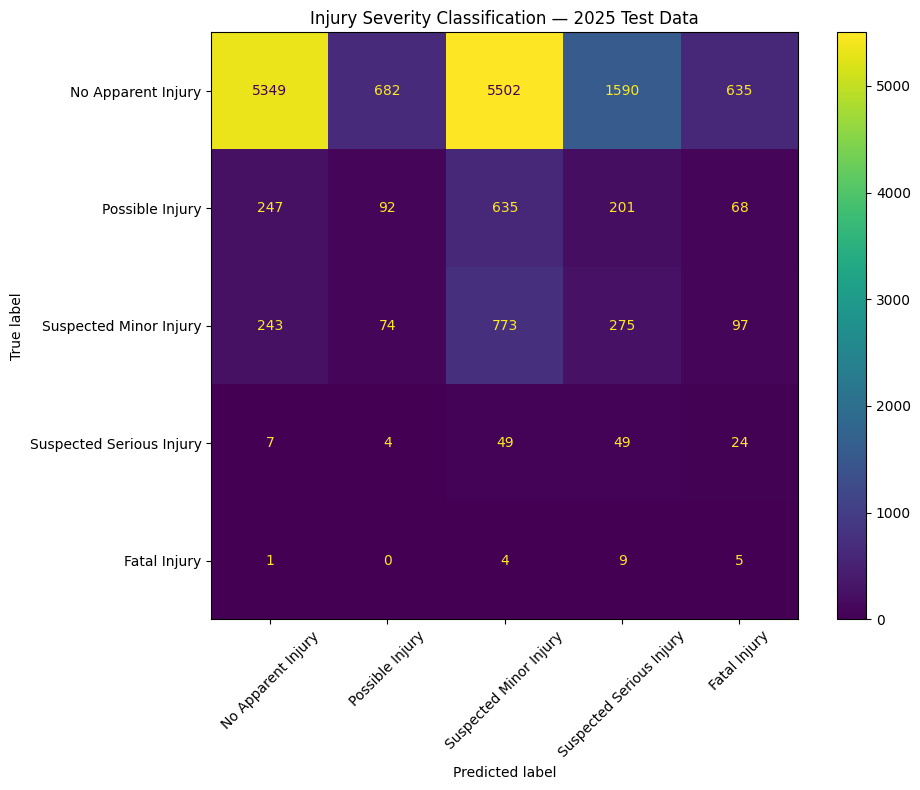

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    ConfusionMatrixDisplay
)

# Calculate performance metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(
    "Balanced Accuracy:",
    round(balanced_accuracy_score(y_test, y_pred), 4)
)
print(
    "Macro F1 Score:",
    round(f1_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    ), 4)
)

# Detailed classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=valid_severity,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=valid_severity
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=valid_severity
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d"
)
plt.title("Injury Severity Classification — 2025 Test Data")
plt.tight_layout()
plt.show()


In [ ]:

# Transform a sample using the fitted preprocessing pipeline
sample_size = min(1000, len(X_test))

X_test_sample = X_test.iloc[:sample_size]

X_test_transformed = baseline_model.named_steps[
    "preprocessor"
].transform(X_test_sample)

# Check for missing values in the transformed data
if hasattr(X_test_transformed, "toarray"):
    transformed_sample = X_test_transformed.toarray()
else:
    transformed_sample = X_test_transformed

print(
    "Missing values after preprocessing:",
    np.isnan(transformed_sample).sum()
)


Missing values after preprocessing: 0


# **Notes: After EDA Imputation**
- Target variable class imbalance is still an issue
- Logistic Regression performed with 37.72% accuracy, 32.46% recall, 17.44% Macro F1. 0 missing values due to imputation. (Overall Poor)

# **Target Variable Class Imbalance Treatment**

In [ ]:
%pip install -q imbalanced-learn

In [ ]:

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

# Baseline: class weighting, without resampling.
baseline_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# Method 1: random oversampling.
random_over_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("resampler", RandomOverSampler(
        sampling_strategy="not majority",
        random_state=42
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Method 2: random undersampling.
# Keep 10,000 observations in the majority class.
undersample_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("resampler", RandomUnderSampler(
        sampling_strategy={
            "No Apparent Injury": 10000
        },
        random_state=42
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

print("Baseline and resampling pipelines defined.")


Baseline and resampling pipelines defined.


Create a 2022–2024 modeling dataset
- df_development is a copy of the 2022-2024 split data (still trying to figure out the imbalance stuff with this rather than directly working on Kelly's df_2022_2025)

In [ ]:

# Keep only 2022–2024 data for model development.
# Do not use the previous 2025 test set.

target = "Injury Severity"

valid_severity = [
    "No Apparent Injury",
    "Possible Injury",
    "Suspected Minor Injury",
    "Suspected Serious Injury",
    "Fatal Injury"
]

features = [
    "Collision Group",
    "Weather",
    "Surface Condition",
    "Light",
    "Traffic Control",
    "Speed Limit",
    "Vehicle Body Type",
    "Vehicle Movement",
    "Vehicle Going Dir",
    "Route Type",
    "Crash Hour",
    "Crash Day of Week",
    "Crash Month"
]

df_development = df_2022_2025[
    df_2022_2025["Crash Year"].isin([2022, 2023, 2024])
].copy()

df_development = df_development[
    df_development[target].isin(valid_severity)
].copy()

print("Development dataset shape:", df_development.shape)

print("\nRecords by year:")
print(df_development["Crash Year"].value_counts().sort_index())

print("\nInjury severity distribution:")
print(df_development[target].value_counts())

print("\nClass proportions:")
print(
    (df_development[target].value_counts(normalize=True) * 100)
    .round(2)
)


Development dataset shape: (53968, 43)

Records by year:
Crash Year
2022    17582
2023    18928
2024    17458
Name: count, dtype: int64

Injury severity distribution:
Injury Severity
No Apparent Injury          44904
Possible Injury              4789
Suspected Minor Injury       3795
Suspected Serious Injury      424
Fatal Injury                   56
Name: count, dtype: int64

Class proportions:
Injury Severity
No Apparent Injury          83.20
Possible Injury              8.87
Suspected Minor Injury       7.03
Suspected Serious Injury     0.79
Fatal Injury                 0.10
Name: proportion, dtype: float64


Make a chronological training/validation split

Note:
- even though we are splitting again, this is NOT a stratified random split

In [ ]:

# Train on 2022–2023 and validate on 2024.

train_data = df_development[
    df_development["Crash Year"].isin([2022, 2023])
].copy()

val_data = df_development[
    df_development["Crash Year"] == 2024
].copy()

X_train = train_data[features]
y_train = train_data[target]

X_val = val_data[features]
y_val = val_data[target]

print("Training records:", len(X_train))
print("Validation records:", len(X_val))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nValidation class distribution:")
print(y_val.value_counts())


Training records: 36510
Validation records: 17458

Training class distribution:
Injury Severity
No Apparent Injury          30473
Possible Injury              3552
Suspected Minor Injury       2179
Suspected Serious Injury      268
Fatal Injury                   38
Name: count, dtype: int64

Validation class distribution:
Injury Severity
No Apparent Injury          14431
Suspected Minor Injury       1616
Possible Injury              1237
Suspected Serious Injury      156
Fatal Injury                   18
Name: count, dtype: int64


Define preprocessing once

In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

numeric_features = [
    "Speed Limit",
    "Crash Hour",
    "Crash Day of Week",
    "Crash Month"
]

categorical_features = [
    "Collision Group",
    "Weather",
    "Surface Condition",
    "Light",
    "Traffic Control",
    "Vehicle Body Type",
    "Vehicle Movement",
    "Vehicle Going Dir",
    "Route Type"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing setup complete.")


Preprocessing setup complete.


Compare imbalance methods

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

models = {
    "Class-weighted Logistic Regression": baseline_pipeline,
    "Random Oversampling": random_over_pipeline,
    "Random Undersampling": undersample_pipeline
}

validation_results = []

for name, model in models.items():
    print(f"\n{'=' * 65}")
    print(name)
    print("=" * 65)

    model.fit(X_train, y_train)
    y_val_pred = model.predict(X_val)

    accuracy = accuracy_score(y_val, y_val_pred)
    balanced_accuracy = balanced_accuracy_score(y_val, y_val_pred)
    macro_f1 = f1_score(
        y_val,
        y_val_pred,
        labels=valid_severity,
        average="macro",
        zero_division=0
    )

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Balanced Accuracy": balanced_accuracy,
        "Macro F1": macro_f1
    })

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Balanced accuracy: {balanced_accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")

    print("\nClassification report:")
    print(classification_report(
        y_val,
        y_val_pred,
        labels=valid_severity,
        zero_division=0
    ))

validation_comparison = (
    __import__("pandas")
    .DataFrame(validation_results)
    .sort_values("Macro F1", ascending=False)
)

print("\nValidation comparison:")
print(validation_comparison.to_string(index=False))



Class-weighted Logistic Regression
Accuracy: 0.7165
Balanced accuracy: 0.2171
Macro F1: 0.1991

Classification report:
                          precision    recall  f1-score   support

      No Apparent Injury       0.84      0.85      0.84     14431
         Possible Injury       0.09      0.16      0.12      1237
  Suspected Minor Injury       0.04      0.00      0.00      1616
Suspected Serious Injury       0.02      0.07      0.03       156
            Fatal Injury       0.00      0.00      0.00        18

                accuracy                           0.72     17458
               macro avg       0.20      0.22      0.20     17458
            weighted avg       0.70      0.72      0.71     17458


Random Oversampling
Accuracy: 0.6443
Balanced accuracy: 0.2150
Macro F1: 0.1900

Classification report:
                          precision    recall  f1-score   support

      No Apparent Injury       0.84      0.75      0.79     14431
         Possible Injury       0.09      0.28

**Check this gpt interpretation**

The class-weighted logistic regression is currently the best of these three on both balanced accuracy and macro F1. However, those scores remain low.
- Class-weighted logistic regression: identifies some possible and suspected serious injuries, but misses all fatal injuries and nearly all suspected minor injuries.
- Random oversampling: increases recall for possible injuries from 0.16 to 0.28, but does not improve the overall macro F1.
- Random undersampling: achieves the highest accuracy by predicting almost everything as “No Apparent Injury.” It fails to identify any of the four minority classes, so this is not a useful result for our research goal.
The key lesson is that high accuracy does not mean the model can distinguish injury severity well.

# **SMOTENC and SMOTE Consideration?**

Experiment A — Test SMOTENC on the original five-class target

In [ ]:

from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC

# First stage: impute missing values and encode categories for SMOTENC.
smotenc_preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numeric_features),
        ("cat", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ordinal", OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            ))
        ]), categorical_features)
    ],
    verbose_feature_names_out=False
)

# The numeric columns come first, followed by the categorical columns.
categorical_indices = list(
    range(len(numeric_features), len(numeric_features) + len(categorical_features))
)

# Second stage: scale numeric columns and one-hot encode categorical columns.
final_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), list(range(len(numeric_features)))),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=10
        ), categorical_indices)
    ]
)

smotenc_pipeline = ImbPipeline(steps=[
    ("preprocess_for_sampling", smotenc_preprocessor),
    ("resampler", SMOTENC(
        categorical_features=categorical_indices,
        sampling_strategy="not majority",
        random_state=42,
        k_neighbors=5
    )),
    ("preprocessor", final_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Fit ONLY on 2022–2023, then evaluate on 2024.
smotenc_pipeline.fit(X_train, y_train)
y_val_smotenc = smotenc_pipeline.predict(X_val)

print("SMOTENC — five-class target")
print("Accuracy:", round(accuracy_score(y_val, y_val_smotenc), 4))
print("Balanced accuracy:", round(
    balanced_accuracy_score(y_val, y_val_smotenc), 4
))
print("Macro F1:", round(
    f1_score(
        y_val, y_val_smotenc,
        labels=valid_severity,
        average="macro",
        zero_division=0
    ), 4
))

print("\nClassification report:")
print(classification_report(
    y_val,
    y_val_smotenc,
    labels=valid_severity,
    zero_division=0
))


SMOTENC — five-class target
Accuracy: 0.8264
Balanced accuracy: 0.1999
Macro F1: 0.181

Classification report:
                          precision    recall  f1-score   support

      No Apparent Injury       0.83      1.00      0.90     14431
         Possible Injury       0.00      0.00      0.00      1237
  Suspected Minor Injury       0.00      0.00      0.00      1616
Suspected Serious Injury       0.00      0.00      0.00       156
            Fatal Injury       0.00      0.00      0.00        18

                accuracy                           0.83     17458
               macro avg       0.17      0.20      0.18     17458
            weighted avg       0.68      0.83      0.75     17458



Experiment A2 — Consider standard SMOTE as a comparison

In [ ]:

from imblearn.over_sampling import SMOTE
from sklearn.base import clone

smote_pipeline = ImbPipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("resampler", SMOTE(
        sampling_strategy="not majority",
        random_state=42,
        k_neighbors=5
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Training data only is resampled.
smote_pipeline.fit(X_train, y_train)
y_val_smote = smote_pipeline.predict(X_val)

print("Standard SMOTE — five-class target")
print("Accuracy:", round(accuracy_score(y_val, y_val_smote), 4))
print("Balanced accuracy:", round(
    balanced_accuracy_score(y_val, y_val_smote), 4
))
print("Macro F1:", round(
    f1_score(
        y_val, y_val_smote,
        labels=valid_severity,
        average="macro",
        zero_division=0
    ), 4
))

print("\nClassification report:")
print(classification_report(
    y_val,
    y_val_smote,
    labels=valid_severity,
    zero_division=0
))


Standard SMOTE — five-class target
Accuracy: 0.8047
Balanced accuracy: 0.203
Macro F1: 0.1885

Classification report:
                          precision    recall  f1-score   support

      No Apparent Injury       0.83      0.97      0.89     14431
         Possible Injury       0.12      0.02      0.03      1237
  Suspected Minor Injury       0.33      0.00      0.00      1616
Suspected Serious Injury       0.01      0.03      0.02       156
            Fatal Injury       0.00      0.00      0.00        18

                accuracy                           0.80     17458
               macro avg       0.26      0.20      0.19     17458
            weighted avg       0.72      0.80      0.74     17458



Experiment B — Merge suspected serious and fatal injuries

In [ ]:

# Create a separate four-class target.
# Do not overwrite the original five-class target.

severe_fatal_label = "Severe/Fatal Injury"

y_train_4 = y_train.replace({
    "Suspected Serious Injury": severe_fatal_label,
    "Fatal Injury": severe_fatal_label
})

y_val_4 = y_val.replace({
    "Suspected Serious Injury": severe_fatal_label,
    "Fatal Injury": severe_fatal_label
})

severity_4 = [
    "No Apparent Injury",
    "Possible Injury",
    "Suspected Minor Injury",
    severe_fatal_label
]

print("Four-class training distribution:")
print(y_train_4.value_counts())

print("\nFour-class validation distribution:")
print(y_val_4.value_counts())


Four-class training distribution:
Injury Severity
No Apparent Injury        30473
Possible Injury            3552
Suspected Minor Injury     2179
Severe/Fatal Injury         306
Name: count, dtype: int64

Four-class validation distribution:
Injury Severity
No Apparent Injury        14431
Suspected Minor Injury     1616
Possible Injury            1237
Severe/Fatal Injury         174
Name: count, dtype: int64


Now compare class weighting, SMOTENC, and standard SMOTE on this four-class target.

In [ ]:

# Four-class baseline.
baseline_4 = clone(baseline_pipeline)
baseline_4.fit(X_train, y_train_4)
pred_baseline_4 = baseline_4.predict(X_val)

# Four-class SMOTENC.
smotenc_4 = clone(smotenc_pipeline)
smotenc_4.fit(X_train, y_train_4)
pred_smotenc_4 = smotenc_4.predict(X_val)

# Four-class standard SMOTE.
smote_4 = clone(smote_pipeline)
smote_4.fit(X_train, y_train_4)
pred_smote_4 = smote_4.predict(X_val)

four_class_models = {
    "Class-weighted Logistic Regression": pred_baseline_4,
    "SMOTENC": pred_smotenc_4,
    "Standard SMOTE": pred_smote_4
}

four_class_results = []

for name, predictions in four_class_models.items():
    four_class_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val_4, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_val_4, predictions),
        "Macro F1": f1_score(
            y_val_4,
            predictions,
            labels=severity_4,
            average="macro",
            zero_division=0
        )
    })

    print(f"\n{'=' * 60}")
    print(name)
    print("=" * 60)
    print(classification_report(
        y_val_4,
        predictions,
        labels=severity_4,
        zero_division=0
    ))

four_class_comparison = (
    __import__("pandas")
    .DataFrame(four_class_results)
    .sort_values("Macro F1", ascending=False)
)

print("\nFour-class validation comparison:")
print(four_class_comparison.to_string(index=False))



Class-weighted Logistic Regression
                        precision    recall  f1-score   support

    No Apparent Injury       0.84      0.79      0.82     14431
       Possible Injury       0.10      0.18      0.13      1237
Suspected Minor Injury       0.11      0.00      0.00      1616
   Severe/Fatal Injury       0.02      0.20      0.04       174

              accuracy                           0.67     17458
             macro avg       0.27      0.29      0.25     17458
          weighted avg       0.71      0.67      0.68     17458


SMOTENC
                        precision    recall  f1-score   support

    No Apparent Injury       0.83      1.00      0.90     14431
       Possible Injury       0.00      0.00      0.00      1237
Suspected Minor Injury       0.00      0.00      0.00      1616
   Severe/Fatal Injury       1.00      0.01      0.01       174

              accuracy                           0.83     17458
             macro avg       0.46      0.25      0.23 